# **Competition Code**

End-to-end, leak-free V5 Multi-Family Pipeline for 6-Class Emotion Classification (`anger`, `disgust`, `fear`, `joy`, `sadness`, `surprise`) evaluated by Macro-F1.

## 1. Preprocessing Steps

In [1]:
# 1.0 Environment, Hardware & Reproducibility Setup
import gc
import html
import json
import math
import os
import re
import time
import warnings
from collections import Counter
from pathlib import Path

os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from peft import LoraConfig, get_peft_model
from scipy import sparse
from scipy.optimize import minimize
from scipy.special import softmax
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, log_loss
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from torch.utils.data import DataLoader, Dataset, TensorDataset
from transformers import (
    AutoModel,
    AutoModelForCausalLM,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    get_cosine_schedule_with_warmup,
)

torch.set_float32_matmul_precision("high")
SEED = 42
N_SPLITS = 5
K = 6
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path("2026-dm-lab-2-private-competition")
assert DATA_DIR.exists(), f"Missing dataset directory: {DATA_DIR.resolve()}"

np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"Device: {DEV} | PyTorch: {torch.__version__}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)} | VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")


def retry_from_pretrained(loader_fn, *args, retries: int = 4, delay: float = 3.0, **kwargs):
    last_err = None
    for attempt in range(retries):
        try:
            return loader_fn(*args, **kwargs)
        except Exception as exc:
            last_err = exc
            if attempt + 1 < retries:
                wait = delay * (2 ** attempt)
                print(f"[HF retry {attempt + 1}/{retries}] {type(exc).__name__}: {exc}; sleeping {wait:.0f}s", flush=True)
                time.sleep(wait)
    raise last_err


def clip_renorm(probs: np.ndarray, eps: float = 1e-7) -> np.ndarray:
    p = np.clip(np.asarray(probs, dtype=np.float64), eps, 1.0)
    return p / p.sum(axis=-1, keepdims=True)


def temp_scaled_ll(probs_or_logits: np.ndarray, y_true: np.ndarray, is_logits: bool = False) -> tuple[float, float]:
    lp = np.asarray(probs_or_logits, dtype=np.float64) if is_logits else np.log(clip_renorm(probs_or_logits))
    res = minimize(
        lambda t: log_loss(y_true, softmax(lp / t[0], axis=1)),
        x0=[1.0],
        bounds=[(0.2, 12.0)],
        method="L-BFGS-B",
    )
    return float(res.fun), float(res.x[0])


def compute_class_weights(y_arr: np.ndarray, power: float = 0.5) -> np.ndarray:
    counts = np.bincount(y_arr, minlength=K).astype(np.float64)
    return ((len(y_arr) / (K * np.maximum(counts, 1.0))) ** power).astype(np.float32)


def make_sample_weights(y_tr: np.ndarray, nw_tr: np.ndarray, cw_pow: float = 0.5) -> np.ndarray:
    cw = compute_class_weights(y_tr, power=cw_pow)
    sw = cw[y_tr] * nw_tr.astype(np.float32)
    return (sw / sw.mean()).astype(np.float32)


def fit_l2_simplex(
    prob_list: list[np.ndarray],
    y_true: np.ndarray,
    cw_power: float = 0.0,
    lam: float = 0.03,
    mode: str = "arith",
) -> np.ndarray:
    m = len(prob_list)
    if m == 1:
        return np.ones(1, dtype=np.float64)
    y_oh = np.eye(K, dtype=np.float64)[y_true]
    counts = np.bincount(y_true, minlength=K).astype(np.float64)
    cw = (len(y_true) / (K * np.maximum(counts, 1.0))) ** cw_power
    sw = cw[y_true]
    sw /= sw.mean()

    P_stack = np.stack([clip_renorm(p) for p in prob_list], axis=0)
    LogP_stack = np.log(P_stack)
    w0 = np.full(m, 1.0 / m, dtype=np.float64)

    def obj(w: np.ndarray) -> float:
        w = np.clip(w, 0.0, 1.0)
        w /= max(w.sum(), 1e-12)
        if mode == "geom":
            log_mix = np.tensordot(w, LogP_stack, axes=(0, 0))
            log_mix -= log_mix.max(axis=1, keepdims=True)
            p_mix = np.exp(log_mix)
            p_mix /= p_mix.sum(axis=1, keepdims=True)
        else:
            p_mix = np.tensordot(w, P_stack, axes=(0, 0))
        ce = -(y_oh * np.log(np.clip(p_mix, 1e-7, 1.0))).sum(axis=1)
        return float((ce * sw).mean()) + lam * float(((w - w0) ** 2).sum())

    res = minimize(
        obj,
        w0,
        method="SLSQP",
        bounds=[(0.0, 1.0)] * m,
        constraints={"type": "eq", "fun": lambda w: float(w.sum() - 1.0)},
        options={"ftol": 1e-9, "maxiter": 500},
    )
    w_opt = np.clip(res.x, 0.0, 1.0)
    return w_opt / w_opt.sum()


def fit_temp_bias(probs: np.ndarray, y_true: np.ndarray) -> tuple[float, np.ndarray]:
    lp = np.log(clip_renorm(probs))

    def obj(params: np.ndarray) -> float:
        t_s, b = params[0], params[1:]
        q = softmax(lp / t_s + b[None, :], axis=1)
        return float(log_loss(y_true, np.clip(q, 1e-7, 1.0)) + 1e-3 * float((b * b).sum()))

    res = minimize(
        obj,
        np.array([1.0] + [0.0] * K, dtype=np.float64),
        method="L-BFGS-B",
        bounds=[(0.2, 5.0)] + [(-2.0, 2.0)] * K,
    )
    return float(res.x[0]), res.x[1:].astype(np.float64)


def _expected_macro_f1(P: np.ndarray, pred: np.ndarray) -> float:
    total = 0.0
    for c in range(P.shape[1]):
        mask = pred == c
        a_c = P[mask, c].sum()
        b_c = mask.sum() + P[:, c].sum()
        total += (2.0 * a_c / b_c) if b_c > 0 else 0.0
    return total / P.shape[1]


def exact_expected_macro_f1_predict(P: np.ndarray, max_iter: int = 30) -> np.ndarray:
    """Zero-parameter plug-in optimizer maximizing expected Macro-F1 given calibrated probabilities."""
    p = clip_renorm(P)
    pred = p.argmax(axis=1).copy()
    best_pred = pred.copy()
    best_obj = _expected_macro_f1(p, pred)
    p_col_sum = p.sum(axis=0)

    for _ in range(max_iter):
        counts = np.bincount(pred, minlength=p.shape[1]).astype(np.float64)
        b = counts + p_col_sum
        a = np.array([p[pred == c, c].sum() for c in range(p.shape[1])], dtype=np.float64)
        f = np.where(b > 0, 2.0 * a / b, 0.0)
        scores = (2.0 / np.maximum(b, 1e-8))[None, :] * (p - 0.5 * f[None, :])
        new_pred = scores.argmax(axis=1)
        if np.array_equal(new_pred, pred):
            break
        pred = new_pred
        obj = _expected_macro_f1(p, pred)
        if obj > best_obj:
            best_obj = obj
            best_pred = pred.copy()
    return best_pred


Device: cuda | PyTorch: 2.15.0+cu132
GPU: NVIDIA GeForce RTX 5090 | VRAM: 33.67 GB


In [2]:
# 1.1 Load Competition Data and Merge Tables
with open(DATA_DIR / "final_posts.json", encoding="utf-8") as f:
    df_posts = pd.DataFrame(json.load(f))

df_id = pd.read_csv(DATA_DIR / "data_identification.csv")
df_emotion = pd.read_csv(DATA_DIR / "emotion.csv")
df_sample_sub = pd.read_csv(DATA_DIR / "sampleSubmission.csv")

df_all = (
    df_posts
    .merge(df_id, on="post_id", how="left")
    .merge(df_emotion, on="post_id", how="left")
)

print(f"Total records: {len(df_all)}")
print("Split counts:\n", df_all["set"].value_counts(), sep="")
print("\nMissing values per column:\n", df_all.isnull().sum(), sep="")
print(f"Sample submission rows: {len(df_sample_sub)} | columns: {list(df_sample_sub.columns)}")
df_all.head(3)


Total records: 4800
Split counts:
set
train    3360
test     1440
Name: count, dtype: int64

Missing values per column:
post_id       0
text          0
set           0
label      1440
dtype: int64
Sample submission rows: 1440 | columns: ['post_id', 'label']


,post_id,text,set,label
0,f8bv5zh,Thought it looked weird as well.,train,disgust
1,q0rr1l9,Bear died in a pit,train,disgust
2,p94rwgk,I have endured worse.,train,sadness


Train deduplicated: 3360 -> 3326 rows | Test aligned: 1440 rows
Class counts: {'anger': 667, 'disgust': 451, 'fear': 282, 'joy': 870, 'sadness': 619, 'surprise': 437}


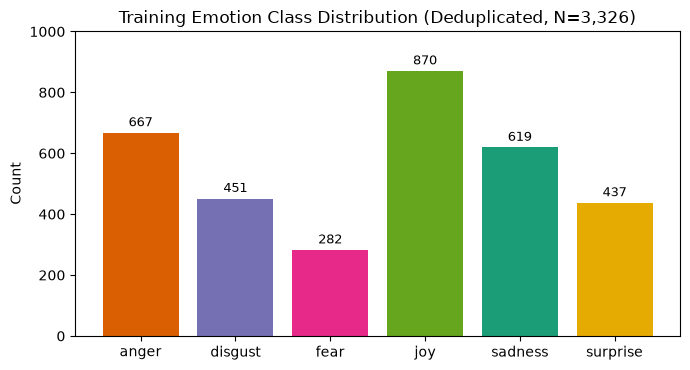

In [3]:
# 1.2 Text Cleaning, Deduplication, Label Encoding, EDA Plot & Stratified 5-Fold Split
PIDGIN_RE = re.compile(
    r"\b(?:una|wetin|dey|abeg|wahala|pikin|sabi|chop|comot|shey|abi|sha|sef|omo|jare|naim)\b",
    re.IGNORECASE,
)


def clean_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = html.unescape(text)
    text = text.replace("\u2019", "'").replace("\u2018", "'").replace("\u201c", '"').replace("\u201d", '"')
    text = re.sub(r"https?://\S+|www\.\S+", "[URL]", text)
    text = re.sub(r"(^|\s)>+", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def minimal_clean(text: str) -> str:
    if not isinstance(text, str):
        return ""
    return re.sub(r"\s+", " ", html.unescape(text)).strip()


def twitter_prep(text: str) -> str:
    t = minimal_clean(text).replace("@<username>", "@user")
    return re.sub(r"##URL##|https?://\S+|www\.\S+", "http", t)


df_all["clean_text"] = df_all["text"].apply(clean_text)
train_raw = df_all[df_all["set"] == "train"].reset_index(drop=True)
sub_id_col = "post_id" if "post_id" in df_sample_sub.columns else "id"
test_df = df_sample_sub[[sub_id_col]].rename(columns={sub_id_col: "post_id"}).merge(
    df_all.drop(columns=["label"]), on="post_id", how="left"
).reset_index(drop=True)

train_df = train_raw.drop_duplicates(subset=["clean_text", "label"], keep="first").reset_index(drop=True)
LABELS = sorted(train_df["label"].unique())
label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for i, l in enumerate(LABELS)}
train_df["target"] = train_df["label"].map(label2id)
y = train_df["target"].values

fls = list(StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED).split(np.zeros(len(y)), y))
print(f"Train deduplicated: {len(train_raw)} -> {len(train_df)} rows | Test aligned: {len(test_df)} rows")
print("Class counts:", train_df["label"].value_counts().reindex(LABELS).to_dict())

fig, ax = plt.subplots(figsize=(7, 3.8))
counts = train_df["label"].value_counts().reindex(LABELS)
bars = ax.bar(counts.index, counts.values, color=["#d95f02", "#7570b3", "#e7298a", "#66a61e", "#1b9e77", "#e6ab02"])
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 12, f"{int(b.get_height())}", ha="center", va="bottom", fontsize=9)
ax.set_title("Training Emotion Class Distribution (Deduplicated, N=3,326)")
ax.set_ylabel("Count")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.show()


## 2. Feature Engineering Steps

In [4]:
# 2.1 Domain Structural Cues (26-d), Pretrained Emotion Logits (emo7), English NLI (fp32 TF32), Qwen3-Emb-8B & LaBSE
def _word_rep_stats(text: str) -> tuple[float, float]:
    words = text.lower().split()
    n = len(words)
    if n == 0:
        return 1.0, 0.0
    unique_ratio = len(set(words)) / n
    if n < 6:
        return unique_ratio, 0.0
    trigrams = [tuple(words[i : i + 3]) for i in range(n - 2)]
    counts = Counter(trigrams)
    repeated = sum(c - 1 for c in counts.values() if c > 1)
    return unique_ratio, repeated / max(len(trigrams), 1)


def raw_domain_features(df: pd.DataFrame) -> np.ndarray:
    raw = df["text"].fillna("").astype(str)
    ct = df["clean_text"].fillna("").astype(str)
    char_len = ct.str.len().values.astype(np.float32)
    word_len = ct.str.split().str.len().values.astype(np.float32)
    rep_stats = np.array([_word_rep_stats(s) for s in ct], dtype=np.float32)
    feats = np.column_stack([
        raw.str.contains(r"[\u2018\u2019\u201c\u201d]", regex=True).astype(np.float32).values,
        raw.str.contains(r"\[NAME\]", regex=True).astype(np.float32).values,
        raw.str.contains(r"@<username>", regex=True).astype(np.float32).values,
        raw.str.contains(r"@\w+", regex=True).astype(np.float32).values,
        raw.str.contains(r"#\w+", regex=True).astype(np.float32).values,
        raw.str.contains(r"##URL##|https?://|www\.", regex=True).astype(np.float32).values,
        raw.str.contains(r"[\U0001F300-\U0001FAFF]", regex=True).astype(np.float32).values,
        raw.str.contains(r"[^\x00-\x7F]", regex=True).astype(np.float32).values,
        raw.str.contains(r"[\u0400-\u04FF\u0600-\u06FF\u0900-\u097F\u4E00-\u9FFF]", regex=True).astype(np.float32).values,
        raw.str.contains(PIDGIN_RE).astype(np.float32).values,
        ct.str.endswith("?").astype(np.float32).values,
        ct.str.endswith("!").astype(np.float32).values,
        ct.str.endswith(".").astype(np.float32).values,
        (~ct.str.contains(r"[.!?]$", regex=True)).astype(np.float32).values,
        ct.str.count(r"!").astype(np.float32).values,
        ct.str.count(r"\?").astype(np.float32).values,
        ct.str.count(r"[!?]{2,}").astype(np.float32).values,
        ct.str.count(r"\.\.+").astype(np.float32).values,
        raw.str.count(r'["\u201c\u201d]').astype(np.float32).values,
        np.log1p(char_len),
        np.log1p(word_len),
        char_len / np.maximum(word_len, 1.0),
        np.array([sum(1 for c in s if c.isupper()) / max(len(s), 1) for s in ct], dtype=np.float32),
        np.array([sum(1 for w in s.split() if len(w) > 1 and w.isupper() and w not in ("[NAME]", "[URL]")) for s in ct], dtype=np.float32),
        rep_stats[:, 0],
        rep_stats[:, 1],
    ])
    return np.nan_to_num(feats, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)


def sorted_batch_infer(texts: list[str], fn, bs: int) -> np.ndarray:
    order = np.argsort([len(t) for t in texts])
    out = None
    for i in range(0, len(order), bs):
        idx = order[i : i + bs]
        res = fn([texts[j] for j in idx])
        if out is None:
            out = np.zeros((len(texts), res.shape[1]), dtype=np.float32)
        out[idx] = res
    return out


t_fe0 = time.time()
n_tr = len(train_df)
tr_raw_texts = [minimal_clean(t) for t in train_df["text"].tolist()]
te_raw_texts = [minimal_clean(t) for t in test_df["text"].tolist()]
all_raw_texts = tr_raw_texts + te_raw_texts

dom_tr = raw_domain_features(train_df)
dom_te = raw_domain_features(test_df)
print(f"[domain] {dom_tr.shape}")

EMO_MODELS = [
    ("SamLowe/roberta-base-go_emotions", "softmax", False),
    ("j-hartmann/emotion-english-roberta-large", "softmax", False),
    ("j-hartmann/emotion-english-distilroberta-base", "softmax", False),
    ("cardiffnlp/twitter-roberta-large-emotion-latest", "softmax", True),
    ("cardiffnlp/twitter-roberta-base-emotion-multilabel-latest", "sigmoid", True),
    ("bhadresh-savani/roberta-base-emotion", "softmax", False),
    ("michellejieli/emotion_text_classifier", "softmax", False),
]

emo_blocks = []
with torch.no_grad():
    for m_name, act, tw_fmt in EMO_MODELS:
        tok = retry_from_pretrained(AutoTokenizer.from_pretrained, m_name)
        mod = retry_from_pretrained(AutoModelForSequenceClassification.from_pretrained, m_name).to(DEV).eval()
        prep = [twitter_prep(t) if tw_fmt else t for t in all_raw_texts]

        def _run_emo(batch_t):
            enc = tok(batch_t, padding=True, truncation=True, max_length=256, return_tensors="pt").to(DEV)
            with torch.autocast("cuda", dtype=torch.bfloat16):
                lg = mod(**enc).logits.float()
            pr = torch.sigmoid(lg) if act == "sigmoid" else torch.softmax(lg, dim=-1)
            return np.hstack([lg.cpu().numpy(), pr.cpu().numpy()])

        emo_blocks.append(sorted_batch_infer(prep, _run_emo, bs=128))
        del mod, tok
        gc.collect()
        torch.cuda.empty_cache()

emo_full = np.hstack(emo_blocks).astype(np.float32)
emo_tr, emo_te = emo_full[:n_tr], emo_full[n_tr:]
print(f"[emo7] {emo_tr.shape} ({time.time() - t_fe0:.1f}s)")

NLI_EN_HYPOTHESES = [
    "The primary emotion expressed in this text is anger.",
    "The primary emotion expressed in this text is disgust.",
    "The primary emotion expressed in this text is fear.",
    "The primary emotion expressed in this text is joy.",
    "The primary emotion expressed in this text is sadness.",
    "The primary emotion expressed in this text is surprise.",
    "The author feels moral disgust, revulsion, or contempt.",
    "The author is furious, hostile, or angry.",
    "The author feels sad, grieving, disappointed, or sorry.",
    "The author is scared, anxious, worried, or afraid.",
    "The author is happy, amused, grateful, loving, or excited.",
    "The author is shocked, astonished, or surprised.",
    "This text is sarcastic or ironic.",
    "The author is complaining or expressing annoyance.",
    "This text describes something gross, creepy, weird, or nasty.",
    "This text describes tragedy, death, injury, or loss.",
    "This text expresses disbelief or asks a rhetorical question.",
    "This text is joking or laughing.",
]

t_nli0 = time.time()
tok_nli = retry_from_pretrained(AutoTokenizer.from_pretrained, "MoritzLaurer/DeBERTa-v3-large-mnli-fever-anli-ling-wanli")
mod_nli = retry_from_pretrained(AutoModelForSequenceClassification.from_pretrained, "MoritzLaurer/DeBERTa-v3-large-mnli-fever-anli-ling-wanli", dtype=torch.float32).to(DEV).eval()
id2l_nli = {int(k): v.lower() for k, v in mod_nli.config.id2label.items()}
ent_id = next(k for k, v in id2l_nli.items() if "entail" in v)
con_id = next(k for k, v in id2l_nli.items() if "contra" in v)

order_nli = np.argsort([len(t) for t in all_raw_texts])
nli_feats = np.zeros((len(all_raw_texts), len(NLI_EN_HYPOTHESES) * 3), dtype=np.float32)
with torch.no_grad():
    for hi, hyp in enumerate(NLI_EN_HYPOTHESES):
        col = hi * 3
        for i in range(0, len(order_nli), 128):
            idx = order_nli[i : i + 128]
            bt = [all_raw_texts[j] for j in idx]
            enc = tok_nli(bt, [hyp] * len(bt), padding=True, truncation=True, max_length=256, return_tensors="pt").to(DEV)
            lg = mod_nli(**enc).logits.float()
            ent, con = lg[:, ent_id].cpu().numpy(), lg[:, con_id].cpu().numpy()
            nli_feats[idx, col] = ent
            nli_feats[idx, col + 1] = con
            nli_feats[idx, col + 2] = ent - con
del mod_nli, tok_nli
gc.collect()
torch.cuda.empty_cache()
ne_tr, ne_te = nli_feats[:n_tr], nli_feats[n_tr:]
print(f"[nli_en] {ne_tr.shape} ({time.time() - t_nli0:.1f}s)")


def last_token_pool(last_hidden_states: torch.Tensor, attention_mask: torch.Tensor) -> torch.Tensor:
    if attention_mask[:, -1].sum() == attention_mask.shape[0]:
        return last_hidden_states[:, -1]
    seq_lens = attention_mask.sum(dim=1) - 1
    return last_hidden_states[torch.arange(last_hidden_states.shape[0], device=last_hidden_states.device), seq_lens]


@torch.no_grad()
def extract_emb(model_name: str, mode: str, bs: int) -> tuple[np.ndarray, np.ndarray]:
    if mode == "qwen3_emb":
        inst = (
            "Classify the primary emotion (anger, disgust, fear, joy, sadness, surprise) of this "
            "social media post, including slang, sarcasm, Nigerian Pidgin, or translated text."
        )
        texts = [f"Instruct: {inst}\nQuery:{t}" for t in all_raw_texts]
        tok = retry_from_pretrained(AutoTokenizer.from_pretrained, model_name, padding_side="left")
        if tok.pad_token is None:
            tok.pad_token = tok.eos_token
        mod = retry_from_pretrained(AutoModel.from_pretrained, model_name, dtype=torch.bfloat16, attn_implementation="sdpa").to(DEV).eval()
    else:
        texts = all_raw_texts
        tok = retry_from_pretrained(AutoTokenizer.from_pretrained, model_name)
        mod = retry_from_pretrained(AutoModel.from_pretrained, model_name, dtype=torch.bfloat16).to(DEV).eval()

    def _run_e(bt):
        enc = tok(bt, padding=True, truncation=True, max_length=256, return_tensors="pt").to(DEV)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            out = mod(**enc)
        vec = last_token_pool(out.last_hidden_state.float(), enc["attention_mask"]) if mode == "qwen3_emb" else out.pooler_output.float()
        return F.normalize(vec, p=2, dim=1).cpu().numpy()

    arr = sorted_batch_infer(texts, _run_e, bs=bs).astype(np.float32)
    del mod, tok
    gc.collect()
    torch.cuda.empty_cache()
    return arr[:n_tr], arr[n_tr:]


t_emb0 = time.time()
el_tr, el_te = extract_emb("sentence-transformers/LaBSE", mode="pooler", bs=128)
eq_tr, eq_te = extract_emb("Qwen/Qwen3-Embedding-8B", mode="qwen3_emb", bs=32)
print(f"[embeddings] LaBSE={el_tr.shape}, Qwen3-Emb-8B={eq_tr.shape} ({time.time() - t_emb0:.1f}s)")
assert all(np.all(np.isfinite(x)) for x in (dom_tr, dom_te, emo_tr, emo_te, ne_tr, ne_te, el_tr, el_te, eq_tr, eq_te))


[domain] (3326, 26)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

... (4 outputs left out)

[nli_en] (3326, 54) (68.8s)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[embeddings] LaBSE=(3326, 768), Qwen3-Emb-8B=(3326, 4096) (33.4s)


In [5]:
# 2.2 Leak-Free Out-of-Fold Noise-Aware Sample Weights (strictly fit inside each fold's training split)
t_nw0 = time.time()
tr_clean_arr = np.asarray(train_df["clean_text"].tolist(), dtype=object)
noise_weights_v2 = np.zeros((N_SPLITS, n_tr), dtype=np.float32)
tab_nw_all = np.hstack([emo_tr, ne_tr, dom_tr]).astype(np.float32)
emb_nw_all = np.hstack([eq_tr, el_tr * 0.6]).astype(np.float32)

for fold, (tr, va) in enumerate(fls):
    y_tr = y[tr]
    sc_nw = StandardScaler()
    T_tr_nw = sc_nw.fit_transform(tab_nw_all[tr]).astype(np.float32)
    E_tr_nw = emb_nw_all[tr]

    wt_vec = TfidfVectorizer(ngram_range=(1, 3), max_features=40000, sublinear_tf=True, min_df=2, strip_accents="unicode")
    ct_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), max_features=50000, sublinear_tf=True, min_df=3)
    Xsp_tr_nw = sparse.hstack([wt_vec.fit_transform([tr_raw_texts[i] for i in tr]), ct_vec.fit_transform([tr_clean_arr[i] for i in tr])]).tocsr()

    inner_skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
    in_preds = [np.zeros((len(tr), K), dtype=np.float32) for _ in range(4)]
    for ia, ib in inner_skf.split(tr, y_tr):
        in_preds[0][ib] = LogisticRegression(C=1.5, max_iter=1500, class_weight="balanced", random_state=42).fit(Xsp_tr_nw[ia], y_tr[ia]).predict_proba(Xsp_tr_nw[ib])
        in_preds[1][ib] = LogisticRegression(C=0.04, max_iter=2000, random_state=42).fit(T_tr_nw[ia], y_tr[ia]).predict_proba(T_tr_nw[ib])
        in_preds[2][ib] = LogisticRegression(C=1.5, max_iter=2000, random_state=42).fit(E_tr_nw[ia], y_tr[ia]).predict_proba(E_tr_nw[ib])
        in_preds[3][ib] = LogisticRegression(C=0.5, max_iter=2000, random_state=42).fit(
            np.hstack([T_tr_nw[ia] * 0.10, E_tr_nw[ia]]), y_tr[ia]
        ).predict_proba(np.hstack([T_tr_nw[ib] * 0.10, E_tr_nw[ib]]))

    p_stack = [clip_renorm(p) for p in in_preds]
    w_nw = fit_l2_simplex(p_stack, y_tr, cw_power=0.0, lam=0.0, mode="arith")
    inner_prob = sum(wi * pi for wi, pi in zip(w_nw, p_stack))
    self_conf = inner_prob[np.arange(len(tr)), y_tr]
    nw = np.zeros(len(tr), dtype=np.float32)
    for c in range(K):
        m = y_tr == c
        ratio = self_conf[m] / max(float(self_conf[m].mean()), 1e-6)
        w_c = np.clip(ratio, 0.35, 1.30)
        w_c *= m.sum() / w_c.sum()
        nw[m] = w_c
    noise_weights_v2[fold, tr] = nw

print(f"Computed noise_weights_v2 across 5 folds in {time.time() - t_nw0:.1f}s | mean={noise_weights_v2[noise_weights_v2 > 0].mean():.3f}")


Computed noise_weights_v2 across 5 folds in 447.0s | mean=1.000


In [6]:
# 2.3 Dual 14B LLM Reasoning & Retrieval-Augmented In-Context Features (Qwen3-14B + Microsoft Phi-4)
def _format_chat(tok, sys_prompt: str, user_prompt: str, asst_prefix: str = "", disable_thinking: bool = False) -> str:
    msgs = [{"role": "system", "content": sys_prompt}, {"role": "user", "content": user_prompt}]
    if disable_thinking:
        try:
            p = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False)
        except TypeError:
            p = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    else:
        p = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    return p + asst_prefix


@torch.inference_mode()
def score_llm_prompts(base_model, head_w: torch.Tensor, tok, prompts: list[str], bs: int = 16, max_len: int = 384) -> np.ndarray:
    try:
        in_dev = base_model.embed_tokens.weight.device
    except Exception:
        in_dev = next(base_model.parameters()).device
    order = np.argsort([len(p) for p in prompts])
    out = np.zeros((len(prompts), head_w.shape[0]), dtype=np.float32)
    i = 0
    while i < len(order):
        idx = order[i : i + bs]
        enc = tok([prompts[j] for j in idx], padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(in_dev)
        assert (enc["attention_mask"][:, -1] == 1).all()
        try:
            with torch.autocast("cuda", dtype=torch.bfloat16, enabled=torch.cuda.is_available()):
                h = base_model(**enc, use_cache=False).last_hidden_state[:, -1, :].to(DEV).float()
            out[idx] = (h @ head_w.T).cpu().numpy()
            i += bs
        except torch.OutOfMemoryError:
            torch.cuda.empty_cache()
            if bs <= 1:
                raise
            bs = max(1, bs // 2)
            print(f"  [OOM fallback] bs -> {bs}", flush=True)
    return out


def load_causal_base_safe(model_id: str, head_id_groups: list[list[int]], force_gpu_gb: int | None = None):
    gc.collect()
    torch.cuda.empty_cache()
    causal = retry_from_pretrained(
        AutoModelForCausalLM.from_pretrained,
        model_id,
        dtype=torch.bfloat16,
        device_map="cpu",
        low_cpu_mem_usage=True,
        attn_implementation="sdpa",
    )
    heads = [causal.lm_head.weight[ids].detach().float().clone().to(DEV) for ids in head_id_groups]
    base = causal.model
    del causal.lm_head, causal
    gc.collect()
    torch.cuda.empty_cache()

    free_gb = torch.cuda.mem_get_info()[0] / (1024 ** 3) if torch.cuda.is_available() else 0.0
    if force_gpu_gb is None and free_gb >= 29.0:
        print(f"[{model_id}] Dedicated GPU mode: free={free_gb:.2f} GiB -> loading full base to CUDA", flush=True)
        base = base.to(DEV).eval()
    else:
        from accelerate import dispatch_model, infer_auto_device_map

        gpu_budget_gb = force_gpu_gb if force_gpu_gb is not None else max(4, int(free_gb - 3.0))
        print(f"[{model_id}] Shared GPU dispatch mode: free={free_gb:.2f} GiB -> max_memory gpu0={gpu_budget_gb}GiB + cpu=64GiB", flush=True)
        no_split = getattr(base, "_no_split_modules", ["Qwen3DecoderLayer", "Phi3DecoderLayer"])
        dmap = infer_auto_device_map(
            base,
            max_memory={0: f"{gpu_budget_gb}GiB", "cpu": "64GiB"},
            no_split_module_classes=no_split,
            dtype=torch.bfloat16,
        )
        base = dispatch_model(base, device_map=dmap).eval()
    return base, heads


def unload_base(base_model) -> None:
    try:
        from accelerate.hooks import remove_hook_from_submodules
        remove_hook_from_submodules(base_model)
    except Exception:
        pass
    del base_model
    gc.collect()
    torch.cuda.empty_cache()


# ---- A. Qwen/Qwen3-14B Single Load: llm14b_multi (39-d) + 5-Fold 8-Shot RAG Logits ----
t_q14 = time.time()
QWEN14_ID = "Qwen/Qwen3-14B"
tok_q14 = retry_from_pretrained(AutoTokenizer.from_pretrained, QWEN14_ID)
tok_q14.padding_side = "left"
if tok_q14.pad_token is None:
    tok_q14.pad_token = tok_q14.eos_token

q_sp_ids = [tok_q14.encode(" " + l, add_special_tokens=False)[0] for l in LABELS]
q_pl_ids = [tok_q14.encode(l, add_special_tokens=False)[0] for l in LABELS]
q_yn_ids = [tok_q14.encode(" yes", add_special_tokens=False)[0], tok_q14.encode(" no", add_special_tokens=False)[0]]

base_q14, (W_q_sp, W_q_pl, W_q_yn) = load_causal_base_safe(QWEN14_ID, [q_sp_ids, q_pl_ids, q_yn_ids])

Q_SYS_EKMAN = "Classify the primary emotion expressed in this social media post into exactly one of: anger, disgust, fear, joy, sadness, surprise. Output ONLY the single lowercase emotion word."
Q_SYS_BOUNDARY = (
    "Carefully distinguish between closely confused emotions in this social media post:\n"
    "- disgust: revulsion, gross/creepy/weird/nasty things, moral contempt, 'wtf/sickening', strong distaste\n"
    "- anger: hostility, rage, cursing at someone/something, indignation, frustration\n"
    "- sadness: grief, loss, injury, regret, feeling sorry, disappointment\n"
    "- fear: threat, danger, anxiety, worry, panic\n"
    "- joy: happiness, humor, amusement, love, gratitude, pride, optimism\n"
    "- surprise: shock, disbelief, astonishment, unexpected revelation\n"
    "Classify the primary emotion. Output ONLY the single lowercase emotion word."
)
Q_SYS_PRAGMATICS = (
    "You are a cross-cultural pragmatics expert. Before classifying the emotion, decode any sarcasm, "
    "irony, rhetorical question, internet slang, Nigerian Pidgin (e.g. 'una', 'dey', 'abeg', 'wetin'), "
    "or awkward machine translation to identify the speaker's true underlying emotion among: "
    "anger, disgust, fear, joy, sadness, surprise. Output ONLY the single lowercase emotion word."
)
Q_BIN_PROBES = [
    "Does this post primarily express disgust, revulsion, creepiness, or moral contempt (rather than anger or sadness)? Reply ONLY 'yes' or 'no'.",
    "Is this post sarcastic, ironic, mocking, or asking a rhetorical jab? Reply ONLY 'yes' or 'no'.",
    "Does this post express active anger, hostility, outrage, or frustration (rather than disgust or sadness)? Reply ONLY 'yes' or 'no'.",
]

q_blocks = []
for sp_msg in (Q_SYS_EKMAN, Q_SYS_BOUNDARY, Q_SYS_PRAGMATICS):
    pr_list = [_format_chat(tok_q14, sp_msg, f"Post: {t}", "Emotion:", disable_thinking=True) for t in all_raw_texts]
    lg = score_llm_prompts(base_q14, W_q_sp, tok_q14, pr_list, bs=16, max_len=320)
    q_blocks.extend([lg, softmax(lg / 4.0, axis=1).astype(np.float32)])
for b_sys in Q_BIN_PROBES:
    pr_list = [_format_chat(tok_q14, b_sys, f"Post: {t}", "Answer:", disable_thinking=True) for t in all_raw_texts]
    lg_yn = score_llm_prompts(base_q14, W_q_yn, tok_q14, pr_list, bs=16, max_len=256)
    q_blocks.append((lg_yn[:, 0] - lg_yn[:, 1])[:, None].astype(np.float32))

q_multi_all = np.hstack(q_blocks).astype(np.float32)
l14_tr, l14_te = q_multi_all[:n_tr], q_multi_all[n_tr:]

Q_SYS_RAG = (
    "Classify the primary emotion expressed in the social media post into exactly one category: "
    "anger, disgust, fear, joy, sadness, or surprise.\n"
    "Posts may be informal, sarcastic, Nigerian Pidgin, or machine-translated. Reply with ONLY the single lowercase emotion word."
)


def build_qwen_rag_prompts(query_texts, query_embs, bank_texts, bank_labels, bank_embs, k_shot=8, exclude_clean=None, bank_clean=None):
    sims = query_embs @ bank_embs.T
    if exclude_clean is not None and bank_clean is not None:
        sims[exclude_clean[:, None] == bank_clean[None, :]] = -1e9
    prompts = []
    for i in range(len(query_texts)):
        top = np.argpartition(-sims[i], k_shot)[:k_shot]
        top = top[np.argsort(sims[i, top])]
        lines = [f"Post: {bank_texts[idx][:280].replace(chr(10), ' ')}\nEmotion: {LABELS[bank_labels[idx]]}" for idx in top]
        lines.append(f"Post: {query_texts[i][:450].replace(chr(10), ' ')}\nEmotion:")
        prompts.append(_format_chat(tok_q14, Q_SYS_RAG, "\n\n".join(lines), "", disable_thinking=True))
    return prompts


q_ro_lg = np.zeros((n_tr, K), dtype=np.float32)
q_rt_lg = np.zeros((N_SPLITS, len(test_df), K), dtype=np.float32)
for k_f, (tr, va) in enumerate(fls):
    va_pr = build_qwen_rag_prompts([tr_raw_texts[j] for j in va], eq_tr[va], [tr_raw_texts[j] for j in tr], y[tr], eq_tr[tr], k_shot=8, exclude_clean=tr_clean_arr[va], bank_clean=tr_clean_arr[tr])
    te_pr = build_qwen_rag_prompts(te_raw_texts, eq_te, [tr_raw_texts[j] for j in tr], y[tr], eq_tr[tr], k_shot=8)
    q_ro_lg[va] = score_llm_prompts(base_q14, W_q_pl, tok_q14, va_pr, bs=8, max_len=1024)
    q_rt_lg[k_f] = score_llm_prompts(base_q14, W_q_pl, tok_q14, te_pr, bs=8, max_len=1024)

unload_base(base_q14)
del base_q14, W_q_sp, W_q_pl, W_q_yn, tok_q14
gc.collect()
torch.cuda.empty_cache()
print(f"[Qwen3-14B] multi={l14_tr.shape} | RAG rawF1={f1_score(y, q_ro_lg.argmax(1), average='macro'):.4f} | VRAM={torch.cuda.memory_allocated()/1e9:.2f} GB | elapsed={time.time()-t_q14:.1f}s")

# ---- B. microsoft/phi-4 Single Load: phi4_multi (39-d) + Clean-Exemplar 5-Fold 8-Shot RAG Logits ----
t_p4 = time.time()
PHI4_ID = "microsoft/phi-4"
tok_p4 = retry_from_pretrained(AutoTokenizer.from_pretrained, PHI4_ID)
tok_p4.padding_side = "left"
if tok_p4.pad_token is None:
    tok_p4.pad_token = tok_p4.eos_token

p_lbl_ids = [tok_p4.encode(" " + l, add_special_tokens=False)[0] for l in LABELS]
p_yn_ids = [tok_p4.encode(" " + w, add_special_tokens=False)[0] for w in ("yes", "no")]

base_p4, (W_p_lbl, W_p_yn) = load_causal_base_safe(PHI4_ID, [p_lbl_ids, p_yn_ids])

P4_SYS_EKMAN = "You are an expert Ekman emotion annotator. Classify the post's primary emotion into exactly one of: anger, disgust, fear, joy, sadness, surprise. Reply with one word only."
P4_SYS_BOUNDARY = (
    "Classify the writer's primary emotion (anger, disgust, fear, joy, sadness, surprise).\n"
    "Pay careful attention to confusable boundaries:\n"
    "- disgust vs anger: moral revulsion, cringe, nausea, 'gross/ew/pathetic/sickening' -> disgust; hot hostility, yelling, cursing someone -> anger.\n"
    "- surprise vs joy/anger/fear: sudden shock, disbelief, 'what?!', 'no way', unexpected twist -> surprise.\n"
    "- fear vs sadness: looming threat/anxiety -> fear; loss, grief, disappointment, hurt -> sadness."
)
P4_SYS_PRAGMATICS = (
    "Interpret the true underlying emotion of this social media post (anger, disgust, fear, joy, sadness, surprise), "
    "accounting for sarcasm, irony, rhetorical questions, internet slang, Twitter @mentions, and Nigerian Pidgin or non-English phrases."
)
P4_YN_PROBES = [
    "Is the post ironic, sarcastic, or mocking rather than literal? Answer yes or no.",
    "Does the post express disgust, moral revulsion, cringe, or finding something gross or pathetic? Answer yes or no.",
    "Does the post express sudden shock, astonishment, disbelief, or unexpected surprise? Answer yes or no.",
]
P4_SYS_RAG = "Classify the primary emotion of the final post into exactly one of: anger, disgust, fear, joy, sadness, surprise. Use the labeled examples as calibration."

tr_clean_p4 = [clean_text(t) for t in train_df["text"].tolist()]
te_clean_p4 = [clean_text(t) for t in test_df["text"].tolist()]
te_clean_arr = np.asarray(test_df["clean_text"].tolist(), dtype=object)

p_tr_blocks, p_te_blocks = [], []
for sp_msg in (P4_SYS_EKMAN, P4_SYS_BOUNDARY, P4_SYS_PRAGMATICS):
    lg_tr = score_llm_prompts(base_p4, W_p_lbl, tok_p4, [_format_chat(tok_p4, sp_msg, f"Post: {t}", "Emotion:") for t in tr_clean_p4], bs=16, max_len=384)
    lg_te = score_llm_prompts(base_p4, W_p_lbl, tok_p4, [_format_chat(tok_p4, sp_msg, f"Post: {t}", "Emotion:") for t in te_clean_p4], bs=16, max_len=384)
    p_tr_blocks.extend([lg_tr, softmax(lg_tr, axis=1).astype(np.float32)])
    p_te_blocks.extend([lg_te, softmax(lg_te, axis=1).astype(np.float32)])

for yq in P4_YN_PROBES:
    lg_tr = score_llm_prompts(base_p4, W_p_yn, tok_p4, [_format_chat(tok_p4, "Answer strictly with yes or no.", f"Post: {t}\nQuestion: {yq}", "Answer:") for t in tr_clean_p4], bs=16, max_len=384)
    lg_te = score_llm_prompts(base_p4, W_p_yn, tok_p4, [_format_chat(tok_p4, "Answer strictly with yes or no.", f"Post: {t}\nQuestion: {yq}", "Answer:") for t in te_clean_p4], bs=16, max_len=384)
    p_tr_blocks.append(softmax(lg_tr, axis=1)[:, :1].astype(np.float32))
    p_te_blocks.append(softmax(lg_te, axis=1)[:, :1].astype(np.float32))

p4_tr = np.hstack(p_tr_blocks).astype(np.float32)
p4_te = np.hstack(p_te_blocks).astype(np.float32)

p_ro_lg = np.zeros((n_tr, K), dtype=np.float32)
p_rt_lg = np.zeros((N_SPLITS, len(test_df), K), dtype=np.float32)


def _fmt_p4_rag(q_txt: str, ex_indices: np.ndarray) -> str:
    shots = [f"Post: {tr_clean_p4[idx][:220]}\nEmotion: {LABELS[y[idx]]}" for idx in reversed(ex_indices)]
    return _format_chat(tok_p4, P4_SYS_RAG, "\n\n".join(shots) + f"\n\nPost: {q_txt}", "Emotion:")


for k_f, (tr, va) in enumerate(fls):
    clean_mask = noise_weights_v2[k_f, tr] >= 0.85
    cand_idx = tr[clean_mask] if clean_mask.sum() >= 50 else tr
    sim_va = (eq_tr[va] @ eq_tr[cand_idx].T).astype(np.float32)
    sim_va[tr_clean_arr[va][:, None] == tr_clean_arr[cand_idx][None, :]] = -1e4
    top_va = np.argsort(-sim_va, axis=1)[:, :8]
    va_pr = [_fmt_p4_rag(tr_clean_p4[q], cand_idx[top_va[ri]]) for ri, q in enumerate(va)]

    sim_te = (eq_te @ eq_tr[cand_idx].T).astype(np.float32)
    sim_te[te_clean_arr[:, None] == tr_clean_arr[cand_idx][None, :]] = -1e4
    top_te = np.argsort(-sim_te, axis=1)[:, :8]
    te_pr = [_fmt_p4_rag(te_clean_p4[ri], cand_idx[top_te[ri]]) for ri in range(len(test_df))]

    p_ro_lg[va] = score_llm_prompts(base_p4, W_p_lbl, tok_p4, va_pr, bs=8, max_len=1024)
    p_rt_lg[k_f] = score_llm_prompts(base_p4, W_p_lbl, tok_p4, te_pr, bs=8, max_len=1024)

unload_base(base_p4)
del base_p4, W_p_lbl, W_p_yn, tok_p4
gc.collect()
torch.cuda.empty_cache()
print(f"[Phi-4 14B] multi={p4_tr.shape} | RAG rawF1={f1_score(y, p_ro_lg.argmax(1), average='macro'):.4f} | VRAM={torch.cuda.memory_allocated()/1e9:.2f} GB | elapsed={time.time()-t_p4:.1f}s")


Loading weights:   0%|          | 0/443 [00:00<?, ?it/s]

[Qwen/Qwen3-14B] Dedicated GPU mode: free=30.67 GiB -> loading full base to CUDA


[Qwen3-14B] multi=(3326, 39) | RAG rawF1=0.5732 | VRAM=0.00 GB | elapsed=1043.9s


Loading weights:   0%|          | 0/243 [00:00<?, ?it/s]

[microsoft/phi-4] Dedicated GPU mode: free=30.67 GiB -> loading full base to CUDA


[Phi-4 14B] multi=(3326, 39) | RAG rawF1=0.5735 | VRAM=0.00 GB | elapsed=1051.3s


## 3. Model Implementation Steps

In [7]:
# 3.1 Baseline Model: Word + Char_WB TF-IDF + Regularized Logistic Regression (submission_baseline.csv)
t_b0 = time.time()
oof_base = np.zeros((n_tr, K), dtype=np.float32)
te_base_folds = np.zeros((N_SPLITS, len(test_df), K), dtype=np.float32)

for fold, (tr, va) in enumerate(fls):
    vw = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=30000, sublinear_tf=True)
    vc = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, max_features=50000, sublinear_tf=True)
    X_b_tr = sparse.hstack([vw.fit_transform([tr_clean_arr[i] for i in tr]), vc.fit_transform([tr_clean_arr[i] for i in tr])])
    X_b_va = sparse.hstack([vw.transform([tr_clean_arr[i] for i in va]), vc.transform([tr_clean_arr[i] for i in va])])
    X_b_te = sparse.hstack([vw.transform(te_clean_arr), vc.transform(te_clean_arr)])
    sw_b = make_sample_weights(y[tr], noise_weights_v2[fold, tr], cw_pow=0.5)
    clf_b = LogisticRegression(C=2.0, max_iter=1000)
    clf_b.fit(X_b_tr, y[tr], sample_weight=sw_b)
    oof_base[va] = clip_renorm(clf_b.predict_proba(X_b_va))
    te_base_folds[fold] = clip_renorm(clf_b.predict_proba(X_b_te))

base_f1 = f1_score(y, oof_base.argmax(1), average="macro")
base_acc = accuracy_score(y, oof_base.argmax(1))
base_ll = log_loss(y, clip_renorm(oof_base))
print(f"[Baseline TF-IDF LR] 5-Fold OOF Macro-F1={base_f1:.4f} | Acc={base_acc:.4f} | LL={base_ll:.4f} ({time.time()-t_b0:.1f}s)")
print(classification_report(y, oof_base.argmax(1), target_names=LABELS, digits=4))

sub_base = pd.DataFrame({"id": test_df["post_id"].values, "label": [id2label[i] for i in te_base_folds.mean(axis=0).argmax(axis=1)]})
sub_base.to_csv("submission_baseline.csv", index=False)
print("Saved submission_baseline.csv")


[Baseline TF-IDF LR] 5-Fold OOF Macro-F1=0.5231 | Acc=0.5412 | LL=1.2767 (26.3s)
              precision    recall  f1-score   support

       anger     0.4701    0.5772    0.5182       667
     disgust     0.4355    0.3592    0.3937       451
        fear     0.7267    0.4149    0.5282       282
         joy     0.6027    0.6678    0.6336       870
     sadness     0.5418    0.5654    0.5534       619
    surprise     0.5632    0.4691    0.5119       437

    accuracy                         0.5412      3326
   macro avg     0.5567    0.5089    0.5231      3326
weighted avg     0.5474    0.5412    0.5381      3326

Saved submission_baseline.csv


In [8]:
# 3.2 V5 Stage-1 Super-Meta Learners (Linear, Dual-Branch ResMLP, Bagged HistGBDT, Native RBF-SVM) & Leak-Free Teacher
def cosine_knn_and_centroid_features(
    emb_tr: np.ndarray,
    y_tr: np.ndarray,
    emb_q: np.ndarray,
    clean_tr: np.ndarray | None = None,
    clean_q: np.ndarray | None = None,
    ks: tuple[int, ...] = (7, 15, 35, 75),
    exclude_self: bool = False,
) -> np.ndarray:
    sim = (emb_q @ emb_tr.T).astype(np.float32)
    if exclude_self:
        if clean_tr is not None and clean_q is not None and len(clean_tr) == len(clean_q):
            sim[clean_q[:, None] == clean_tr[None, :]] = -1e4
        elif len(emb_q) == len(emb_tr):
            np.fill_diagonal(sim, -1e4)

    feats = []
    centroids = np.zeros((K, emb_tr.shape[1]), dtype=np.float32)
    for c in range(K):
        mu = emb_tr[y_tr == c].mean(axis=0)
        centroids[c] = mu / (np.linalg.norm(mu) + 1e-8)
    feats.append((emb_q @ centroids.T).astype(np.float32))

    y_oh = np.eye(K, dtype=np.float32)[y_tr]
    max_k = min(max(ks), sim.shape[1])
    top_idx = np.argpartition(-sim, kth=max(0, max_k - 1), axis=1)[:, :max_k]
    row_idx = np.arange(len(emb_q))[:, None]
    top_sims = sim[row_idx, top_idx]
    order = np.argsort(-top_sims, axis=1)
    top_idx, top_sims = top_idx[row_idx, order], top_sims[row_idx, order]
    top_y = y_oh[top_idx]

    for k in ks:
        kk = min(k, top_sims.shape[1])
        s_k = np.clip(top_sims[:, :kk], 0.0, 1.0)
        w_k = np.exp((s_k - s_k[:, :1]) * 12.0) * (s_k > 0.05)
        dist_k = (w_k[:, :, None] * top_y[:, :kk, :]).sum(axis=1)
        feats.append((dist_k / (dist_k.sum(axis=1, keepdims=True) + 1e-6)).astype(np.float32))
        if k == ks[0]:
            feats.append(s_k.mean(axis=1, keepdims=True).astype(np.float32))
    return np.hstack(feats).astype(np.float32)


class ResMLPBlock(nn.Module):
    def __init__(self, dim: int, p_drop: float = 0.35):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.fc1 = nn.Linear(dim, dim * 2)
        self.act = nn.GELU()
        self.drop = nn.Dropout(p_drop)
        self.fc2 = nn.Linear(dim * 2, dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x + self.drop(self.fc2(self.drop(self.act(self.fc1(self.norm(x))))))


class DualBranchResMLP(nn.Module):
    def __init__(self, d_tab: int, d_emb: int, h_tab: int = 192, h_emb: int = 256, p_drop: float = 0.35):
        super().__init__()
        self.tab_in = nn.Sequential(nn.LayerNorm(d_tab), nn.Dropout(0.15), nn.Linear(d_tab, h_tab), nn.GELU())
        self.emb_in = nn.Sequential(nn.Dropout(0.35), nn.Linear(d_emb, h_emb), nn.LayerNorm(h_emb), nn.GELU())
        total_h = h_tab + h_emb
        self.block1 = ResMLPBlock(total_h, p_drop=p_drop)
        self.block2 = ResMLPBlock(total_h, p_drop=p_drop)
        self.head = nn.Sequential(nn.LayerNorm(total_h), nn.Dropout(p_drop), nn.Linear(total_h, K))

    def forward(self, x_tab: torch.Tensor, x_emb: torch.Tensor) -> torch.Tensor:
        h = torch.cat([self.tab_in(x_tab), self.emb_in(x_emb)], dim=-1)
        return self.head(self.block2(self.block1(h)))


def run_resmlp_fold(
    seed_list, tab_tr, y_tr, sw_tr, emb_tr, tab_va, y_va, emb_va, tab_te, emb_te,
    tab_pseudo=None, emb_pseudo=None, teacher_probs=None, pseudo_w=0.6, epochs=22, batch_size=128
):
    y_tr_soft = np.eye(K, dtype=np.float32)[y_tr] * 0.98 + 0.02 / K
    if tab_pseudo is not None and teacher_probs is not None:
        X_tab_all, X_emb_all = np.vstack([tab_tr, tab_pseudo]), np.vstack([emb_tr, emb_pseudo])
        Y_soft_all = np.vstack([y_tr_soft, teacher_probs.astype(np.float32)])
        SW_all = np.concatenate([sw_tr, np.full(len(tab_pseudo), pseudo_w, dtype=np.float32)])
    else:
        X_tab_all, X_emb_all, Y_soft_all, SW_all = tab_tr, emb_tr, y_tr_soft, sw_tr

    t_tab_va, t_emb_va = torch.tensor(tab_va, dtype=torch.float32, device=DEV), torch.tensor(emb_va, dtype=torch.float32, device=DEV)
    t_tab_te, t_emb_te = torch.tensor(tab_te, dtype=torch.float32, device=DEV), torch.tensor(emb_te, dtype=torch.float32, device=DEV)

    va_preds, te_preds = [], []
    for seed in seed_list:
        torch.manual_seed(seed)
        np.random.seed(seed)
        dl = DataLoader(TensorDataset(torch.from_numpy(X_tab_all), torch.from_numpy(X_emb_all), torch.from_numpy(Y_soft_all), torch.from_numpy(SW_all)), batch_size=batch_size, shuffle=True)
        model = DualBranchResMLP(tab_tr.shape[1], emb_tr.shape[1], h_tab=192, h_emb=256, p_drop=0.35).to(DEV)
        opt = torch.optim.AdamW(model.parameters(), lr=8e-4, weight_decay=3e-2)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * len(dl), eta_min=2e-5)
        best_cal_ll, best_va_p, best_te_p = float("inf"), None, None
        for ep in range(epochs):
            model.train()
            for bt, be, by, bsw in dl:
                bt, be, by, bsw = bt.to(DEV), be.to(DEV), by.to(DEV), bsw.to(DEV)
                opt.zero_grad(set_to_none=True)
                with torch.amp.autocast("cuda", dtype=torch.bfloat16):
                    lg = model(bt, be).float()
                    loss = (-(by * F.log_softmax(lg, dim=-1)).sum(dim=-1) * bsw).mean()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.5)
                opt.step()
                sched.step()
            if ep >= 4:
                model.eval()
                with torch.inference_mode():
                    va_lg = model(t_tab_va, t_emb_va).cpu().numpy()
                    cal_ll, _ = temp_scaled_ll(va_lg, y_va, is_logits=True)
                    if cal_ll < best_cal_ll:
                        best_cal_ll = cal_ll
                        best_va_p = torch.softmax(torch.from_numpy(va_lg), dim=-1).numpy()
                        best_te_p = torch.softmax(model(t_tab_te, t_emb_te).cpu(), dim=-1).numpy()
        va_preds.append(best_va_p)
        te_preds.append(best_te_p)
        del model, opt, sched
    del t_tab_va, t_emb_va, t_tab_te, t_emb_te
    gc.collect()
    torch.cuda.empty_cache()
    return clip_renorm(np.mean(va_preds, axis=0)), clip_renorm(np.mean(te_preds, axis=0))


t_s1 = time.time()
base_tab_tr = np.hstack([emo_tr, ne_tr, l14_tr, p4_tr, dom_tr]).astype(np.float32)
base_tab_te = np.hstack([emo_te, ne_te, l14_te, p4_te, dom_te]).astype(np.float32)

gbdt_cfgs = [
    dict(max_depth=3, max_leaf_nodes=15, l2_regularization=3.0, learning_rate=0.03, min_samples_leaf=30, max_iter=550, max_features=0.6),
    dict(max_depth=4, max_leaf_nodes=23, l2_regularization=6.0, learning_rate=0.025, min_samples_leaf=35, max_iter=650, max_features=0.55),
    dict(max_depth=5, max_leaf_nodes=31, l2_regularization=10.0, learning_rate=0.022, min_samples_leaf=40, max_iter=700, max_features=0.5),
    dict(max_depth=3, max_leaf_nodes=15, l2_regularization=5.0, learning_rate=0.035, min_samples_leaf=25, max_iter=500, max_features=0.7),
    dict(max_depth=4, max_leaf_nodes=21, l2_regularization=8.0, learning_rate=0.028, min_samples_leaf=35, max_iter=600, max_features=0.6),
    dict(max_depth=4, max_leaf_nodes=19, l2_regularization=4.0, learning_rate=0.03, min_samples_leaf=30, max_iter=550, max_features=0.65),
]

v5_models = {
    name: (np.zeros((n_tr, K), dtype=np.float32), np.zeros((N_SPLITS, len(test_df), K), dtype=np.float32))
    for name in ("v5_super_linear", "v5_super_resmlp", "v5_super_gbdt", "v5_super_svm")
}
fold_meta_cache = []

for fold, (tr, va) in enumerate(fls):
    y_tr, y_va = y[tr], y[va]
    sw_tr = make_sample_weights(y_tr, noise_weights_v2[fold, tr], cw_pow=0.5)
    mu_q, mu_p = q_ro_lg[tr].mean(axis=0, keepdims=True), p_ro_lg[tr].mean(axis=0, keepdims=True)

    knn_q_tr = cosine_knn_and_centroid_features(eq_tr[tr], y_tr, eq_tr[tr], tr_clean_arr[tr], tr_clean_arr[tr], exclude_self=True)
    knn_q_va = cosine_knn_and_centroid_features(eq_tr[tr], y_tr, eq_tr[va], tr_clean_arr[tr], tr_clean_arr[va], exclude_self=False)
    knn_q_te = cosine_knn_and_centroid_features(eq_tr[tr], y_tr, eq_te, exclude_self=False)

    knn_l_tr = cosine_knn_and_centroid_features(el_tr[tr], y_tr, el_tr[tr], tr_clean_arr[tr], tr_clean_arr[tr], exclude_self=True)
    knn_l_va = cosine_knn_and_centroid_features(el_tr[tr], y_tr, el_tr[va], tr_clean_arr[tr], tr_clean_arr[va], exclude_self=False)
    knn_l_te = cosine_knn_and_centroid_features(el_tr[tr], y_tr, el_te, exclude_self=False)

    scaler = StandardScaler()
    tab_tr = scaler.fit_transform(np.hstack([base_tab_tr[tr], q_ro_lg[tr] - mu_q, p_ro_lg[tr] - mu_p, knn_q_tr, knn_l_tr])).astype(np.float32)
    tab_va = scaler.transform(np.hstack([base_tab_tr[va], q_ro_lg[va] - mu_q, p_ro_lg[va] - mu_p, knn_q_va, knn_l_va])).astype(np.float32)
    tab_te = scaler.transform(np.hstack([base_tab_te, q_rt_lg[fold] - mu_q, p_rt_lg[fold] - mu_p, knn_q_te, knn_l_te])).astype(np.float32)

    emb_tr = np.hstack([eq_tr[tr], el_tr[tr] * 0.6]).astype(np.float32)
    emb_va = np.hstack([eq_tr[va], el_tr[va] * 0.6]).astype(np.float32)
    emb_te = np.hstack([eq_te, el_te * 0.6]).astype(np.float32)
    fold_meta_cache.append((tr, va, tab_tr, tab_va, tab_te, emb_tr, emb_va, emb_te, sw_tr))

    # Linear
    X_lin_tr, X_lin_va, X_lin_te = np.hstack([tab_tr * 0.12, emb_tr]), np.hstack([tab_va * 0.12, emb_va]), np.hstack([tab_te * 0.12, emb_te])
    inner_skf = StratifiedKFold(n_splits=4, shuffle=True, random_state=100 + fold)
    best_c, best_ll = 0.30, float("inf")
    for cand_c in (0.05, 0.15, 0.30, 0.60, 1.20):
        in_oof = np.zeros((len(y_tr), K), dtype=np.float32)
        for itr, iva in inner_skf.split(X_lin_tr, y_tr):
            c_in = LogisticRegression(C=cand_c, max_iter=1000).fit(X_lin_tr[itr], y_tr[itr], sample_weight=sw_tr[itr])
            in_oof[iva] = c_in.predict_proba(X_lin_tr[iva])
        cll, _ = temp_scaled_ll(clip_renorm(in_oof), y_tr)
        if cll < best_ll:
            best_ll, best_c = cll, cand_c
    clf_lin = LogisticRegression(C=best_c, max_iter=1200).fit(X_lin_tr, y_tr, sample_weight=sw_tr)
    v5_models["v5_super_linear"][0][va] = clip_renorm(clf_lin.predict_proba(X_lin_va))
    v5_models["v5_super_linear"][1][fold] = clip_renorm(clf_lin.predict_proba(X_lin_te))

    # ResMLP
    v5_models["v5_super_resmlp"][0][va], v5_models["v5_super_resmlp"][1][fold] = run_resmlp_fold(
        [42 + fold * 10 + s for s in range(5)], tab_tr, y_tr, sw_tr, emb_tr, tab_va, y_va, emb_va, tab_te, emb_te
    )

    # GBDT
    svd_q = TruncatedSVD(n_components=48, random_state=42 + fold)
    svd_l = TruncatedSVD(n_components=24, random_state=42 + fold)
    X_gb_tr = np.hstack([tab_tr, svd_q.fit_transform(eq_tr[tr]), svd_l.fit_transform(el_tr[tr])]).astype(np.float32)
    X_gb_va = np.hstack([tab_va, svd_q.transform(eq_tr[va]), svd_l.transform(el_tr[va])]).astype(np.float32)
    X_gb_te = np.hstack([tab_te, svd_q.transform(eq_te), svd_l.transform(el_te)]).astype(np.float32)
    gb_va, gb_te = [], []
    for ci, cfg_g in enumerate(gbdt_cfgs):
        hgb = HistGradientBoostingClassifier(
            **cfg_g, early_stopping=True, validation_fraction=0.12, n_iter_no_change=25, scoring="loss", random_state=200 + fold * 20 + ci
        ).fit(X_gb_tr, y_tr, sample_weight=sw_tr)
        gb_va.append(hgb.predict_proba(X_gb_va))
        gb_te.append(hgb.predict_proba(X_gb_te))
    v5_models["v5_super_gbdt"][0][va] = clip_renorm(np.mean(gb_va, axis=0))
    v5_models["v5_super_gbdt"][1][fold] = clip_renorm(np.mean(gb_te, axis=0))

    # RBF-SVM
    svc = SVC(C=1.8, kernel="rbf", probability=True, random_state=42 + fold)
    svc.fit(np.hstack([tab_tr * 0.10, emb_tr]), y_tr, sample_weight=sw_tr)
    v5_models["v5_super_svm"][0][va] = clip_renorm(svc.predict_proba(np.hstack([tab_va * 0.10, emb_va])))
    v5_models["v5_super_svm"][1][fold] = clip_renorm(svc.predict_proba(np.hstack([tab_te * 0.10, emb_te])))

for m_name, (m_oof, _) in v5_models.items():
    print(f"  [{m_name:20s}] OOF F1={f1_score(y, m_oof.argmax(1), average='macro'):.4f} | LL={log_loss(y, clip_renorm(m_oof)):.4f}")

# Build leak-free V5 Stage-1 Teacher (never peeks at validation fold k)
teacher_tf_v5 = np.zeros((N_SPLITS, len(test_df), K), dtype=np.float32)
teacher_oof_check = np.zeros((n_tr, K), dtype=np.float32)
prob_comps = [v5_models[n] for n in ("v5_super_linear", "v5_super_resmlp", "v5_super_gbdt", "v5_super_svm")]
for fold, (tr, va) in enumerate(fls):
    cal_tr, cal_va, cal_te = [], [], []
    for oof_m, tf_m in prob_comps:
        _, t_m = temp_scaled_ll(oof_m[tr], y[tr])
        cal_tr.append(clip_renorm(softmax(np.log(clip_renorm(oof_m[tr])) / t_m, axis=1)))
        cal_va.append(clip_renorm(softmax(np.log(clip_renorm(oof_m[va])) / t_m, axis=1)))
        cal_te.append(clip_renorm(softmax(np.log(clip_renorm(tf_m[fold])) / t_m, axis=1)))
    for ro_lg, rt_lg in ((q_ro_lg, q_rt_lg), (p_ro_lg, p_rt_lg)):
        mu = ro_lg[tr].mean(axis=0, keepdims=True)
        _, t_r = temp_scaled_ll(ro_lg[tr] - mu, y[tr], is_logits=True)
        cal_tr.append(clip_renorm(softmax((ro_lg[tr] - mu) / t_r, axis=1)))
        cal_va.append(clip_renorm(softmax((ro_lg[va] - mu) / t_r, axis=1)))
        cal_te.append(clip_renorm(softmax((rt_lg[fold] - mu) / t_r, axis=1)))
    w_t = fit_l2_simplex(cal_tr, y[tr], cw_power=0.0, lam=0.03, mode="arith")
    teacher_oof_check[va] = clip_renorm(sum(wi * pi for wi, pi in zip(w_t, cal_va)))
    teacher_tf_v5[fold] = clip_renorm(sum(wi * pi for wi, pi in zip(w_t, cal_te)))

print(f"[V5 Stage-1 Teacher] OOF F1={f1_score(y, teacher_oof_check.argmax(1), average='macro'):.4f} | LL={log_loss(y, teacher_oof_check):.4f} ({time.time()-t_s1:.1f}s)")


  [v5_super_linear     ] OOF F1=0.6560 | LL=0.9640
  [v5_super_resmlp     ] OOF F1=0.6521 | LL=1.0821
  [v5_super_gbdt       ] OOF F1=0.6481 | LL=0.9740
  [v5_super_svm        ] OOF F1=0.6574 | LL=0.9522


[V5 Stage-1 Teacher] OOF F1=0.6599 | LL=0.9237 (1027.0s)


In [9]:
# 3.3 Stage-2 Leak-Free Transductive Soft-Distillation Students
WINNING_MODELS = ['v5_super_linear', 'v5_super_resmlp', 'v5_super_gbdt', 'v5_super_svm', 'v5_st2_super_resmlp', 'v5_st2_rob_base_goemo', 'v5_st2_rob_large_ekman', 'v5_st2_qwen3_8b_vlora']
PSEUDO_W = 0.6


def _st2_text_prep(text: str, tw_fmt: bool) -> str:
    return twitter_prep(text) if tw_fmt else minimal_clean(text)


class SoftTextDS(Dataset):
    def __init__(self, enc_dict, targets, hard_labels, weights):
        self.enc, self.t, self.h, self.w = enc_dict, targets, hard_labels, weights

    def __len__(self):
        return len(self.enc["input_ids"])

    def __getitem__(self, i):
        return {"input_ids": self.enc["input_ids"][i], "attention_mask": self.enc["attention_mask"][i], "t": self.t[i], "h": int(self.h[i]), "w": float(self.w[i])}


class TextDS(Dataset):
    def __init__(self, enc_dict):
        self.enc = enc_dict

    def __len__(self):
        return len(self.enc["input_ids"])

    def __getitem__(self, i):
        return {"input_ids": self.enc["input_ids"][i], "attention_mask": self.enc["attention_mask"][i]}


def make_collate(tok):
    return lambda batch: tok.pad([{"input_ids": b["input_ids"], "attention_mask": b["attention_mask"]} for b in batch], return_tensors="pt")


def make_soft_collate(tok):
    def collate(batch):
        out = tok.pad([{"input_ids": b["input_ids"], "attention_mask": b["attention_mask"]} for b in batch], return_tensors="pt")
        out["t"] = torch.tensor(np.stack([b["t"] for b in batch]), dtype=torch.float32)
        out["h"] = torch.tensor([b["h"] for b in batch], dtype=torch.long)
        out["w"] = torch.tensor([b["w"] for b in batch], dtype=torch.float32)
        return out
    return collate


def _pool_last2(hidden_states, attention_mask: torch.Tensor) -> torch.Tensor:
    mask = attention_mask.unsqueeze(-1).float()
    denom = mask.sum(dim=1).clamp(min=1e-6)
    h1, h2 = hidden_states[-1], hidden_states[-2]
    return torch.cat([h1[:, 0, :], (h1 * mask).sum(dim=1) / denom, h2[:, 0, :], (h2 * mask).sum(dim=1) / denom], dim=-1)


class PreservedEmotionEncoder(nn.Module):
    def __init__(self, hf_model, k_orig: int, hidden_size: int, w_init: np.ndarray, b_init: np.ndarray):
        super().__init__()
        self.hf_model = hf_model
        self.proj = nn.Linear(k_orig, 6)
        with torch.no_grad():
            self.proj.weight.copy_(torch.tensor(w_init, dtype=torch.float32))
            self.proj.bias.copy_(torch.tensor(b_init, dtype=torch.float32))
        self.msd_norm = nn.LayerNorm(4 * hidden_size)
        self.dropouts = nn.ModuleList([nn.Dropout(p) for p in (0.10, 0.15, 0.20, 0.25, 0.30)])
        self.msd_head = nn.Linear(4 * hidden_size, 6)
        with torch.no_grad():
            self.msd_head.weight.zero_()
            self.msd_head.bias.zero_()

    def forward(self, input_ids: torch.Tensor, attention_mask: torch.Tensor) -> torch.Tensor:
        out = self.hf_model(input_ids=input_ids, attention_mask=attention_mask, output_hidden_states=True)
        pooled = self.msd_norm(_pool_last2(out.hidden_states, attention_mask).float())
        return self.proj(out.logits.float()) + sum(self.msd_head(dp(pooled)) for dp in self.dropouts) / len(self.dropouts)


class EMA:
    def __init__(self, model: nn.Module, decay: float = 0.995):
        self.decay = decay
        self.shadow = {k: v.detach().clone() for k, v in model.state_dict().items() if v.dtype.is_floating_point}

    def update(self, model: nn.Module):
        with torch.no_grad():
            for k, v in model.state_dict().items():
                if k in self.shadow:
                    self.shadow[k].mul_(self.decay).add_(v.detach(), alpha=1.0 - self.decay)

    def apply_to(self, model: nn.Module) -> dict[str, torch.Tensor]:
        backup = {k: v.detach().clone() for k, v in model.state_dict().items()}
        sd = model.state_dict()
        for k, v in self.shadow.items():
            sd[k].copy_(v)
        return backup


def build_llrd_param_groups(model: nn.Module, base_lr: float, head_mult: float, llrd: float, weight_decay: float = 0.01):
    layer_nums = [int(m.group(1)) for n, _ in model.named_parameters() if (m := re.search(r"encoder\.layer\.(\d+)\.", n))]
    max_layer = max(layer_nums) if layer_nums else 0
    no_decay = ("bias", "LayerNorm.weight", "LayerNorm.bias", "layernorm.weight", "msd_norm")
    groups = {}
    for n, p in model.named_parameters():
        if not p.requires_grad:
            continue
        wd = 0.0 if any(nd in n for nd in no_decay) else weight_decay
        if (m := re.search(r"encoder\.layer\.(\d+)\.", n)):
            lr = base_lr * (llrd ** (max_layer - int(m.group(1))))
        elif "embeddings" in n:
            lr = base_lr * (llrd ** (max_layer + 1))
        elif any(h in n for h in ("proj", "msd_", "classifier", "pooler")):
            lr = base_lr * max(2.0, head_mult * 0.5) if ("pooler" in n or "classifier" in n) else base_lr * head_mult
        else:
            lr = base_lr
        groups.setdefault((round(lr, 12), wd), []).append(p)
    return [{"params": ps, "lr": lr, "weight_decay": wd} for (lr, wd), ps in groups.items()]


@torch.no_grad()
def predict_enc_loader(model: nn.Module, loader: DataLoader) -> np.ndarray:
    model.eval()
    out = []
    for b in loader:
        with torch.amp.autocast("cuda", dtype=torch.bfloat16):
            lg = model(b["input_ids"].to(DEV, non_blocking=True), b["attention_mask"].to(DEV, non_blocking=True)).float()
        out.append(torch.softmax(lg, dim=-1).cpu().numpy())
    return np.vstack(out)


def train_st2_roberta(model_key: str) -> tuple[np.ndarray, np.ndarray]:
    gc.collect()
    torch.cuda.empty_cache()
    CFGS = {
        "rob_base_goemo": dict(name="SamLowe/roberta-base-go_emotions", lr=2.5e-5, head_mult=4.0, bs=32, epochs=4, seeds=[42, 2026], rdrop=0.5, llrd=0.92, tw_fmt=False),
        "rob_large_ekman": dict(name="j-hartmann/emotion-english-roberta-large", lr=1.5e-5, head_mult=4.0, bs=32, epochs=4, seeds=[42, 2026], rdrop=0.5, llrd=0.95, tw_fmt=False),
        "tw_rob_large": dict(name="cardiffnlp/twitter-roberta-large-emotion-latest", lr=1.5e-5, head_mult=4.0, bs=32, epochs=4, seeds=[42, 2026], rdrop=0.5, llrd=0.95, tw_fmt=True),
    }
    cfg = CFGS[model_key]
    tr_tx = np.asarray([_st2_text_prep(t, cfg["tw_fmt"]) for t in train_df["text"].tolist()], dtype=object)
    te_tx = np.asarray([_st2_text_prep(t, cfg["tw_fmt"]) for t in test_df["text"].tolist()], dtype=object)
    tok = retry_from_pretrained(AutoTokenizer.from_pretrained, cfg["name"])
    ev_col, sf_col = make_collate(tok), make_soft_collate(tok)
    te_dl = DataLoader(TextDS(tok(list(te_tx), truncation=True, max_length=224)), batch_size=64, shuffle=False, collate_fn=ev_col, pin_memory=True)

    def _run_fold(seed: int, fold: int, tr: np.ndarray, va: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        torch.manual_seed(seed + fold + 777)
        tx = list(tr_tx[tr]) + list(te_tx)
        t_tr = np.eye(K, dtype=np.float32)[y[tr]] * 0.95 + 0.05 / K
        tgt_all = np.vstack([t_tr, teacher_tf_v5[fold]]).astype(np.float32)
        hard_all = np.concatenate([y[tr], teacher_tf_v5[fold].argmax(1)])
        wt_all = np.concatenate([noise_weights_v2[fold, tr], np.full(len(test_df), PSEUDO_W, dtype=np.float32)])

        tr_dl = DataLoader(SoftTextDS(tok(tx, truncation=True, max_length=224), tgt_all, hard_all, wt_all), batch_size=cfg["bs"], shuffle=True, collate_fn=sf_col, pin_memory=True)
        va_dl = DataLoader(TextDS(tok(list(tr_tx[va]), truncation=True, max_length=224)), batch_size=64, shuffle=False, collate_fn=ev_col, pin_memory=True)

        hf = retry_from_pretrained(AutoModelForSequenceClassification.from_pretrained, cfg["name"], dtype=torch.float32).to(DEV)
        lg_tr_dl = DataLoader(TextDS(tok(list(tr_tx[tr]), truncation=True, max_length=224)), batch_size=64, shuffle=False, collate_fn=ev_col)
        hf.eval()
        with torch.no_grad():
            lgs = [hf(input_ids=b["input_ids"].to(DEV), attention_mask=b["attention_mask"].to(DEV)).logits.float().cpu().numpy() for b in lg_tr_dl]
        lg_tr_arr = np.vstack(lgs)
        lr_init = LogisticRegression(C=0.2, max_iter=2000).fit(lg_tr_arr, y[tr])
        model = PreservedEmotionEncoder(hf, lg_tr_arr.shape[1], hf.config.hidden_size, lr_init.coef_, lr_init.intercept_).to(DEV)

        ema = EMA(model, decay=0.995)
        opt = torch.optim.AdamW(build_llrd_param_groups(model, cfg["lr"], cfg["head_mult"], cfg["llrd"], 0.01))
        sch = get_cosine_schedule_with_warmup(opt, int(0.1 * len(tr_dl) * cfg["epochs"]), len(tr_dl) * cfg["epochs"])
        cw = torch.tensor(compute_class_weights(y[tr], 0.5) / compute_class_weights(y[tr], 0.5).mean(), dtype=torch.float32, device=DEV)

        y_va = y[va]
        snaps = []
        mid_step = max(1, len(tr_dl) // 2)

        def _snap():
            nonlocal snaps
            vp_raw = predict_enc_loader(model, va_dl)
            ll_raw, _ = temp_scaled_ll(vp_raw, y_va)
            backup = ema.apply_to(model)
            vp_ema = predict_enc_loader(model, va_dl)
            ll_ema, _ = temp_scaled_ll(vp_ema, y_va)
            if ll_ema <= ll_raw:
                use_vp, use_ll, state = vp_ema, ll_ema, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            else:
                use_vp, use_ll, state = vp_raw, ll_raw, {k: v.detach().cpu().clone() for k, v in backup.items()}
            model.load_state_dict(backup)
            snaps.append((use_ll, use_vp, state))
            snaps.sort(key=lambda x: x[0])
            snaps = snaps[:2]

        for ep in range(cfg["epochs"]):
            model.train()
            for step, b in enumerate(tr_dl, 1):
                opt.zero_grad(set_to_none=True)
                ids, mask, tgt, hard, wt = b["input_ids"].to(DEV), b["attention_mask"].to(DEV), b["t"].to(DEV), b["h"].to(DEV), b["w"].to(DEV)
                sw = cw[hard] * wt
                sw_d, wt_d = sw.sum().clamp(min=1e-6), wt.sum().clamp(min=1e-6)
                with torch.amp.autocast("cuda", dtype=torch.bfloat16):
                    lg1, lg2 = model(ids, mask).float(), model(ids, mask).float()
                    l1 = (-(tgt * F.log_softmax(lg1, dim=-1)).sum(dim=-1) * sw).sum() / sw_d
                    l2 = (-(tgt * F.log_softmax(lg2, dim=-1)).sum(dim=-1) * sw).sum() / sw_d
                    p1, p2, lp1, lp2 = F.softmax(lg1, -1), F.softmax(lg2, -1), F.log_softmax(lg1, -1), F.log_softmax(lg2, -1)
                    kl = 0.5 * (F.kl_div(lp1, p2, reduction="none").sum(-1) + F.kl_div(lp2, p1, reduction="none").sum(-1))
                    loss = 0.5 * (l1 + l2) + cfg["rdrop"] * ((kl * wt).sum() / wt_d)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step()
                sch.step()
                ema.update(model)
                if ep >= 1 and step == mid_step:
                    _snap()
                    model.train()
            _snap()

        va_p = 0.65 * snaps[0][1] + 0.35 * snaps[1][1] if len(snaps) >= 2 else snaps[0][1]
        model.load_state_dict({k: v.to(DEV) for k, v in snaps[0][2].items()})
        tp1 = predict_enc_loader(model, te_dl)
        if len(snaps) >= 2:
            model.load_state_dict({k: v.to(DEV) for k, v in snaps[1][2].items()})
            te_p = 0.65 * tp1 + 0.35 * predict_enc_loader(model, te_dl)
        else:
            te_p = tp1
        del model, hf, ema, opt, sch, snaps, cw, tr_dl, va_dl, lg_tr_dl
        return va_p, te_p

    oof = np.zeros((n_tr, K), dtype=np.float32)
    te_folds = np.zeros((N_SPLITS, len(test_df), K), dtype=np.float32)
    for seed in cfg["seeds"]:
        for fold, (tr, va) in enumerate(fls):
            va_p, te_p = _run_fold(seed, fold, tr, va)
            oof[va] += va_p / len(cfg["seeds"])
            te_folds[fold] += te_p / len(cfg["seeds"])
            gc.collect()
            torch.cuda.empty_cache()
    print(f"  [{model_key}] finished | residual VRAM={torch.cuda.memory_allocated()/1e9:.2f} GB", flush=True)
    return clip_renorm(oof), clip_renorm(te_folds)


class EmbLoraClassifier(nn.Module):
    def __init__(self, peft_encoder: nn.Module, w_init: np.ndarray, b_init: np.ndarray):
        super().__init__()
        self.encoder = peft_encoder
        self.score_head = nn.Linear(w_init.shape[1], w_init.shape[0], bias=True)
        with torch.no_grad():
            self.score_head.weight.copy_(torch.tensor(w_init, dtype=torch.float32))
            self.score_head.bias.copy_(torch.tensor(b_init, dtype=torch.float32))

    def forward(self, input_ids: torch.Tensor, attention_mask: torch.Tensor) -> torch.Tensor:
        with torch.autocast("cuda", dtype=torch.bfloat16):
            out = self.encoder(input_ids=input_ids, attention_mask=attention_mask, use_cache=False)
            vec = last_token_pool(out.last_hidden_state.float(), attention_mask)
        return self.score_head(F.normalize(vec, p=2, dim=1))


def train_st2_qwen3_emb8b_lora() -> tuple[np.ndarray, np.ndarray]:
    gc.collect()
    torch.cuda.empty_cache()
    inst = (
        "Classify the primary emotion (anger, disgust, fear, joy, sadness, surprise) of this "
        "social media post, including slang, sarcasm, Nigerian Pidgin, or translated text."
    )
    tok = retry_from_pretrained(AutoTokenizer.from_pretrained, "Qwen/Qwen3-Embedding-8B", padding_side="left")
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    tr_tx = [f"Instruct: {inst}\nQuery:{t}" for t in tr_raw_texts]
    te_tx = [f"Instruct: {inst}\nQuery:{t}" for t in te_raw_texts]

    @torch.no_grad()
    def _pred_emb(mod, texts_p):
        mod.eval()
        out = np.zeros((len(texts_p), K), dtype=np.float32)
        ord_i = np.argsort([len(p) for p in texts_p])
        for i in range(0, len(ord_i), 24):
            b = ord_i[i : i + 24]
            enc = tok([texts_p[j] for j in b], padding=True, truncation=True, max_length=256, return_tensors="pt")
            out[b] = torch.softmax(mod(enc["input_ids"].to(DEV), enc["attention_mask"].to(DEV)), dim=-1).cpu().numpy()
        return out

    def _run_fold(fold: int, tr: np.ndarray, va: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        torch.manual_seed(42 + fold + 777)
        rng = np.random.RandomState(42 + fold + 777)
        lr_init = LogisticRegression(C=2.0, max_iter=2000).fit(eq_tr[tr], y[tr])
        base = retry_from_pretrained(
            AutoModel.from_pretrained, "Qwen/Qwen3-Embedding-8B", dtype=torch.bfloat16, device_map="cpu", low_cpu_mem_usage=True, attn_implementation="sdpa"
        )
        peft_enc = get_peft_model(base, LoraConfig(r=16, lora_alpha=32, lora_dropout=0.10, target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]))
        peft_enc.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
        peft_enc.enable_input_require_grads()
        model = EmbLoraClassifier(peft_enc, lr_init.coef_, lr_init.intercept_).to(DEV)
        for p in model.parameters():
            if p.requires_grad:
                p.data = p.data.float()
        lora_p = [p for n, p in model.named_parameters() if p.requires_grad and "score_head" not in n]
        head_p = [p for n, p in model.named_parameters() if p.requires_grad and "score_head" in n]
        opt = torch.optim.AdamW([{"params": lora_p, "lr": 4e-5}, {"params": head_p, "lr": 3e-4}], weight_decay=0.02)

        all_tx = [tr_tx[j] for j in tr] + te_tx
        tgt_all = np.vstack([np.eye(K, dtype=np.float32)[y[tr]] * 0.95 + 0.05 / K, teacher_tf_v5[fold]]).astype(np.float32)
        hard_all = np.concatenate([y[tr], teacher_tf_v5[fold].argmax(1)])
        wt_all = np.concatenate([noise_weights_v2[fold, tr], np.full(len(test_df), PSEUDO_W, dtype=np.float32)])
        cw = torch.tensor(compute_class_weights(y[tr], 0.5) / compute_class_weights(y[tr], 0.5).mean(), dtype=torch.float32, device=DEV)
        steps_ep = math.ceil(len(all_tx) / 16)
        sch = get_cosine_schedule_with_warmup(opt, int(0.1 * steps_ep * 3), steps_ep * 3)
        va_tx, y_va, snaps, mid = [tr_tx[j] for j in va], y[va], [], max(1, steps_ep // 2)

        def _snap_emb():
            nonlocal snaps
            vp = _pred_emb(model, va_tx)
            cll, _ = temp_scaled_ll(vp, y_va)
            snaps.append((cll, vp, {k: v.detach().cpu().clone() for k, v in model.named_parameters() if v.requires_grad}))
            snaps.sort(key=lambda x: x[0])
            snaps = snaps[:2]

        for ep in range(3):
            model.train()
            idx = np.arange(len(all_tx))
            rng.shuffle(idx)
            for st, i in enumerate(range(0, len(idx), 16), 1):
                b = idx[i : i + 16]
                opt.zero_grad(set_to_none=True)
                sw_b = cw[torch.tensor(hard_all[b], dtype=torch.long, device=DEV)] * torch.tensor(wt_all[b], dtype=torch.float32, device=DEV)
                denom = sw_b.sum().clamp(min=1e-6)
                tgt_b = torch.tensor(tgt_all[b], dtype=torch.float32, device=DEV)
                for mb in range(0, len(b), 8):
                    sub_b = b[mb : mb + 8]
                    enc = tok([all_tx[j] for j in sub_b], padding=True, truncation=True, max_length=256, return_tensors="pt")
                    lg = model(enc["input_ids"].to(DEV), enc["attention_mask"].to(DEV))
                    loss = (-(tgt_b[mb : mb + 8] * F.log_softmax(lg, -1)).sum(-1) * sw_b[mb : mb + 8]).sum() / denom
                    loss.backward()
                torch.nn.utils.clip_grad_norm_(lora_p + head_p, 1.0)
                opt.step()
                sch.step()
                if ep >= 1 and st == mid:
                    _snap_emb()
                    model.train()
            _snap_emb()

        va_p = 0.65 * snaps[0][1] + 0.35 * snaps[1][1] if len(snaps) >= 2 else snaps[0][1]
        pdict = dict(model.named_parameters())
        with torch.no_grad():
            for k, v in snaps[0][2].items():
                pdict[k].copy_(v.to(DEV))
        tp1 = _pred_emb(model, te_tx)
        if len(snaps) >= 2:
            with torch.no_grad():
                for k, v in snaps[1][2].items():
                    pdict[k].copy_(v.to(DEV))
            te_p = 0.65 * tp1 + 0.35 * _pred_emb(model, te_tx)
        else:
            te_p = tp1
        del model, peft_enc, base, opt, sch, snaps, lora_p, head_p, pdict, cw
        return va_p, te_p

    oof = np.zeros((n_tr, K), dtype=np.float32)
    te_folds = np.zeros((N_SPLITS, len(test_df), K), dtype=np.float32)
    for fold, (tr, va) in enumerate(fls):
        gc.collect()
        torch.cuda.empty_cache()
        oof[va], te_folds[fold] = _run_fold(fold, tr, va)
        gc.collect()
        torch.cuda.empty_cache()
        print(f"  [qwen3_emb8b_lora fold {fold}] done | residual VRAM={torch.cuda.memory_allocated()/1e9:.2f} GB", flush=True)
    return clip_renorm(oof), clip_renorm(te_folds)


class VerbalizerClassifier(nn.Module):
    def __init__(self, peft_backbone: nn.Module, init_weight: torch.Tensor, init_bias: torch.Tensor):
        super().__init__()
        self.backbone = peft_backbone
        self.score_head = nn.Linear(init_weight.shape[1], init_weight.shape[0], bias=True)
        with torch.no_grad():
            wc = init_weight.float() - init_weight.float().mean(dim=0, keepdim=True)
            self.score_head.weight.copy_(wc * 0.20)
            self.score_head.bias.copy_(init_bias.float())

    def forward(self, input_ids: torch.Tensor, attention_mask: torch.Tensor) -> torch.Tensor:
        with torch.autocast("cuda", dtype=torch.bfloat16):
            out = self.backbone(input_ids=input_ids, attention_mask=attention_mask, use_cache=False)
        return self.score_head(out.last_hidden_state[:, -1, :].float())


def train_st2_qwen3_8b_vlora() -> tuple[np.ndarray, np.ndarray]:
    gc.collect()
    torch.cuda.empty_cache()
    tok = retry_from_pretrained(AutoTokenizer.from_pretrained, "Qwen/Qwen3-8B")
    tok.padding_side = "left"
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    label_ids = [tok.encode(" " + l, add_special_tokens=False)[0] for l in LABELS]
    sys_m = "Classify the primary emotion (anger, disgust, fear, joy, sadness, surprise) of the social media post. Posts may be informal, sarcastic, Nigerian Pidgin, or machine-translated. Output ONLY the single lowercase emotion word."
    tr_pr = [_format_chat(tok, sys_m, f"Post: {t}", "Emotion:", disable_thinking=True) for t in tr_raw_texts]
    te_pr = [_format_chat(tok, sys_m, f"Post: {t}", "Emotion:", disable_thinking=True) for t in te_raw_texts]

    @torch.no_grad()
    def _pred_v(mod, prompts_p):
        mod.eval()
        out = np.zeros((len(prompts_p), K), dtype=np.float32)
        ord_i = np.argsort([len(p) for p in prompts_p])
        for i in range(0, len(ord_i), 24):
            b = ord_i[i : i + 24]
            enc = tok([prompts_p[j] for j in b], padding=True, truncation=True, max_length=256, return_tensors="pt")
            out[b] = torch.softmax(mod(enc["input_ids"].to(DEV), enc["attention_mask"].to(DEV)), dim=-1).cpu().numpy()
        return out

    def _run_fold(fold: int, tr: np.ndarray, va: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        torch.manual_seed(42 + fold + 777)
        rng = np.random.RandomState(42 + fold + 777)
        clm = retry_from_pretrained(
            AutoModelForCausalLM.from_pretrained, "Qwen/Qwen3-8B", dtype=torch.bfloat16, device_map="cpu", low_cpu_mem_usage=True, attn_implementation="sdpa"
        )
        w_init = clm.lm_head.weight[label_ids].detach().float().clone()
        base = clm.model
        del clm.lm_head, clm
        gc.collect()
        peft_b = get_peft_model(base, LoraConfig(r=16, lora_alpha=32, lora_dropout=0.10, target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]))
        peft_b.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
        peft_b.enable_input_require_grads()
        counts = np.bincount(y[tr], minlength=K).astype(np.float32)
        lp = np.log(np.maximum(counts, 1.0) / counts.sum())
        lp -= lp.mean()
        model = VerbalizerClassifier(peft_b, w_init, torch.tensor(lp, dtype=torch.float32)).to(DEV)
        for p in model.parameters():
            if p.requires_grad:
                p.data = p.data.float()
        lora_p = [p for n, p in model.named_parameters() if p.requires_grad and "score_head" not in n]
        head_p = [p for n, p in model.named_parameters() if p.requires_grad and "score_head" in n]
        opt = torch.optim.AdamW([{"params": lora_p, "lr": 6e-5}, {"params": head_p, "lr": 2e-4}], weight_decay=0.02)

        all_pr = [tr_pr[j] for j in tr] + te_pr
        tgt_all = np.vstack([np.eye(K, dtype=np.float32)[y[tr]] * 0.95 + 0.05 / K, teacher_tf_v5[fold]]).astype(np.float32)
        hard_all = np.concatenate([y[tr], teacher_tf_v5[fold].argmax(1)])
        wt_all = np.concatenate([noise_weights_v2[fold, tr], np.full(len(test_df), PSEUDO_W, dtype=np.float32)])
        cw = torch.tensor(compute_class_weights(y[tr], 0.5) / compute_class_weights(y[tr], 0.5).mean(), dtype=torch.float32, device=DEV)
        steps_ep = math.ceil(len(all_pr) / 16)
        sch = get_cosine_schedule_with_warmup(opt, int(0.1 * steps_ep * 3), steps_ep * 3)
        va_pr, y_va, snaps, mid = [tr_pr[j] for j in va], y[va], [], max(1, steps_ep // 2)

        def _snap_v():
            nonlocal snaps
            vp = _pred_v(model, va_pr)
            cll, _ = temp_scaled_ll(vp, y_va)
            snaps.append((cll, vp, {k: v.detach().cpu().clone() for k, v in model.named_parameters() if v.requires_grad}))
            snaps.sort(key=lambda x: x[0])
            snaps = snaps[:2]

        for ep in range(3):
            model.train()
            idx = np.arange(len(all_pr))
            rng.shuffle(idx)
            for st, i in enumerate(range(0, len(idx), 16), 1):
                b = idx[i : i + 16]
                opt.zero_grad(set_to_none=True)
                sw_b = cw[torch.tensor(hard_all[b], dtype=torch.long, device=DEV)] * torch.tensor(wt_all[b], dtype=torch.float32, device=DEV)
                denom = sw_b.sum().clamp(min=1e-6)
                tgt_b = torch.tensor(tgt_all[b], dtype=torch.float32, device=DEV)
                for mb in range(0, len(b), 8):
                    sub_b = b[mb : mb + 8]
                    enc = tok([all_pr[j] for j in sub_b], padding=True, truncation=True, max_length=256, return_tensors="pt")
                    lg = model(enc["input_ids"].to(DEV), enc["attention_mask"].to(DEV))
                    loss = (-(tgt_b[mb : mb + 8] * F.log_softmax(lg, -1)).sum(-1) * sw_b[mb : mb + 8]).sum() / denom
                    loss.backward()
                torch.nn.utils.clip_grad_norm_(lora_p + head_p, 1.0)
                opt.step()
                sch.step()
                if ep >= 1 and st == mid:
                    _snap_v()
                    model.train()
            _snap_v()

        va_p = 0.65 * snaps[0][1] + 0.35 * snaps[1][1] if len(snaps) >= 2 else snaps[0][1]
        pdict = dict(model.named_parameters())
        with torch.no_grad():
            for k, v in snaps[0][2].items():
                pdict[k].copy_(v.to(DEV))
        tp1 = _pred_v(model, te_pr)
        if len(snaps) >= 2:
            with torch.no_grad():
                for k, v in snaps[1][2].items():
                    pdict[k].copy_(v.to(DEV))
            te_p = 0.65 * tp1 + 0.35 * _pred_v(model, te_pr)
        else:
            te_p = tp1
        del model, peft_b, base, opt, sch, snaps, lora_p, head_p, pdict, cw
        return va_p, te_p

    oof = np.zeros((n_tr, K), dtype=np.float32)
    te_folds = np.zeros((N_SPLITS, len(test_df), K), dtype=np.float32)
    for fold, (tr, va) in enumerate(fls):
        gc.collect()
        torch.cuda.empty_cache()
        oof[va], te_folds[fold] = _run_fold(fold, tr, va)
        gc.collect()
        torch.cuda.empty_cache()
        print(f"  [qwen3_8b_vlora fold {fold}] done | residual VRAM={torch.cuda.memory_allocated()/1e9:.2f} GB", flush=True)
    return clip_renorm(oof), clip_renorm(te_folds)


t_s2 = time.time()
if "v5_st2_super_resmlp" in WINNING_MODELS:
    oof_st2_mlp = np.zeros((n_tr, K), dtype=np.float32)
    tf_st2_mlp = np.zeros((N_SPLITS, len(test_df), K), dtype=np.float32)
    for fold, (tr, va, tab_tr, tab_va, tab_te, emb_tr, emb_va, emb_te, sw_tr) in enumerate(fold_meta_cache):
        oof_st2_mlp[va], tf_st2_mlp[fold] = run_resmlp_fold(
            [500 + fold * 10 + s for s in range(5)], tab_tr, y[tr], sw_tr, emb_tr, tab_va, y[va], emb_va, tab_te, emb_te,
            tab_pseudo=tab_te, emb_pseudo=emb_te, teacher_probs=teacher_tf_v5[fold], pseudo_w=PSEUDO_W
        )
    v5_models["v5_st2_super_resmlp"] = (oof_st2_mlp, tf_st2_mlp)

for r_key in ("rob_base_goemo", "rob_large_ekman", "tw_rob_large"):
    r_tag = f"v5_st2_{r_key}"
    if r_tag in WINNING_MODELS:
        v5_models[r_tag] = train_st2_roberta(r_key)

if "v5_st2_qwen3_emb8b_lora" in WINNING_MODELS:
    v5_models["v5_st2_qwen3_emb8b_lora"] = train_st2_qwen3_emb8b_lora()

if "v5_st2_qwen3_8b_vlora" in WINNING_MODELS:
    v5_models["v5_st2_qwen3_8b_vlora"] = train_st2_qwen3_8b_vlora()

for m_name in WINNING_MODELS:
    m_oof, _ = v5_models[m_name]
    print(f"  [Active {m_name:24s}] OOF F1={f1_score(y, m_oof.argmax(1), average='macro'):.4f} | LL={log_loss(y, clip_renorm(m_oof)):.4f}")
print(f"Stage-2 distillation complete in {time.time()-t_s2:.1f}s")


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

... (23 outputs left out)

  [qwen3_8b_vlora fold 3] done | residual VRAM=0.00 GB


Loading weights:   0%|          | 0/399 [00:00<?, ?it/s]

  [qwen3_8b_vlora fold 4] done | residual VRAM=0.00 GB


  [Active v5_super_linear         ] OOF F1=0.6560 | LL=0.9640
  [Active v5_super_resmlp         ] OOF F1=0.6521 | LL=1.0821
  [Active v5_super_gbdt           ] OOF F1=0.6481 | LL=0.9740
  [Active v5_super_svm            ] OOF F1=0.6574 | LL=0.9522
  [Active v5_st2_super_resmlp     ] OOF F1=0.6578 | LL=1.0034
  [Active v5_st2_rob_base_goemo   ] OOF F1=0.6319 | LL=1.0159
  [Active v5_st2_rob_large_ekman  ] OOF F1=0.6351 | LL=1.0356
  [Active v5_st2_qwen3_8b_vlora   ] OOF F1=0.6295 | LL=0.9944
Stage-2 distillation complete in 3605.7s


                                                                 Model  Macro_F1  Accuracy  LogLoss
                                        Baseline (Word+Char TF-IDF LR)    0.5231    0.5412   1.2767
                                                       v5_super_linear    0.6560    0.6708   0.9640
                                                       v5_super_resmlp    0.6521    0.6720   1.0821
                                                         v5_super_gbdt    0.6481    0.6660   0.9740
                                                          v5_super_svm    0.6574    0.6759   0.9522
                                                   v5_st2_super_resmlp    0.6578    0.6762   1.0034
                                                 v5_st2_rob_base_goemo    0.6319    0.6518   1.0159
                                                v5_st2_rob_large_ekman    0.6351    0.6518   1.0356
                                                 v5_st2_qwen3_8b_vlora    0.6295    0.6518   0.9944


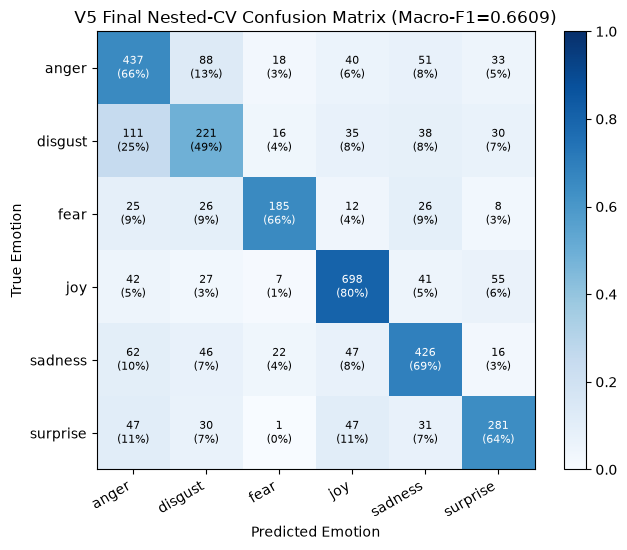


Saved verified submission.csv! Predicted class distribution:
label
anger       327
disgust     185
fear        112
joy         358
sadness     261
surprise    197
Name: count, dtype: int64


In [10]:
# 3.4 Strictly Nested Outer 5-Fold CV Ensemble, Report, Confusion Matrix & Final Submission Export
CW_POWER = 0.0
LAM = 0.03
COMB_MODE = 'arith'
PP_MODE = 'expected_f1'
BAYES_BIAS = False
CFG_NAME = 'V5_Full_Emb8B_VLora :: L2(0.03)-LL-ExpF1'

oof_ens = np.zeros((n_tr, K), dtype=np.float64)
te_folds_ens = np.zeros((N_SPLITS, len(test_df), K), dtype=np.float64)
pred_ens = np.zeros(n_tr, dtype=np.int64)
fold_weights = []


def _blend(plist, w, mode):
    ps = np.stack([clip_renorm(p) for p in plist], axis=0)
    if mode == "geom":
        return clip_renorm(softmax(np.tensordot(w, np.log(ps), axes=(0, 0)), axis=1))
    return clip_renorm(np.tensordot(w, ps, axes=(0, 0)))


for k_f, (tr, va) in enumerate(fls):
    tr_cal, va_cal, te_cal = [], [], []
    for tag in WINNING_MODELS:
        m_oof, m_tf = v5_models[tag]
        _, t_m = temp_scaled_ll(m_oof[tr], y[tr])
        tr_cal.append(clip_renorm(softmax(np.log(clip_renorm(m_oof[tr])) / t_m, axis=1)))
        va_cal.append(clip_renorm(softmax(np.log(clip_renorm(m_oof[va])) / t_m, axis=1)))
        te_cal.append(clip_renorm(softmax(np.log(clip_renorm(m_tf[k_f])) / t_m, axis=1)))

    if CW_POWER < 0:
        w_f = np.full(len(WINNING_MODELS), 1.0 / len(WINNING_MODELS), dtype=np.float64)
    else:
        w_f = fit_l2_simplex(tr_cal, y[tr], cw_power=CW_POWER, lam=LAM, mode=COMB_MODE)
    fold_weights.append(w_f)

    p_tr_b = _blend(tr_cal, w_f, COMB_MODE)
    p_va_b = _blend(va_cal, w_f, COMB_MODE)
    p_te_b = _blend(te_cal, w_f, COMB_MODE)

    if BAYES_BIAS:
        t_e, b_e = fit_temp_bias(p_tr_b, y[tr])
        oof_ens[va] = clip_renorm(softmax(np.log(p_va_b) / t_e + b_e[None, :], axis=1))
        te_folds_ens[k_f] = clip_renorm(softmax(np.log(p_te_b) / t_e + b_e[None, :], axis=1))
    else:
        _, t_e = temp_scaled_ll(p_tr_b, y[tr])
        oof_ens[va] = clip_renorm(softmax(np.log(p_va_b) / t_e, axis=1))
        te_folds_ens[k_f] = clip_renorm(softmax(np.log(p_te_b) / t_e, axis=1))

    pred_ens[va] = exact_expected_macro_f1_predict(oof_ens[va]) if PP_MODE == "expected_f1" else oof_ens[va].argmax(axis=1)

raw_f1 = f1_score(y, oof_ens.argmax(axis=1), average="macro")
ens_f1 = f1_score(y, pred_ens, average="macro")
ens_acc = accuracy_score(y, pred_ens)
ens_ll = log_loss(y, clip_renorm(oof_ens))
ens_fold_f1s = [round(float(f1_score(y[va], pred_ens[va], average="macro")), 4) for _, va in fls]

summary_rows = [
    {
        "Model": "Baseline (Word+Char TF-IDF LR)",
        "Macro_F1": round(base_f1, 4),
        "Accuracy": round(base_acc, 4),
        "LogLoss": round(base_ll, 4),
    }
]
for tag in WINNING_MODELS:
    m_oof, _ = v5_models[tag]
    summary_rows.append({
        "Model": tag,
        "Macro_F1": round(float(f1_score(y, m_oof.argmax(1), average="macro")), 4),
        "Accuracy": round(float(accuracy_score(y, m_oof.argmax(1))), 4),
        "LogLoss": round(float(log_loss(y, clip_renorm(m_oof))), 4),
    })
summary_rows.append({
    "Model": f"FINAL V5 Nested-CV Ensemble ({CFG_NAME})",
    "Macro_F1": round(ens_f1, 4),
    "Accuracy": round(ens_acc, 4),
    "LogLoss": round(ens_ll, 4),
})
display_df = pd.DataFrame(summary_rows)
print(display_df.to_string(index=False))
print(f"\n[FINAL V5 ENSEMBLE] ppMacro-F1={ens_f1:.4f} | rawMacro-F1={raw_f1:.4f} | Acc={ens_acc:.4f} | LL={ens_ll:.4f}")
print(f"Per-fold Macro-F1: {ens_fold_f1s}")
print("Mean fold weights:", {t: round(float(w), 4) for t, w in zip(WINNING_MODELS, np.mean(fold_weights, axis=0))})
print("\nClassification Report (Out-Of-Fold):")
print(classification_report(y, pred_ens, target_names=LABELS, digits=4))

cm = confusion_matrix(y, pred_ens)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.8, 5.6))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0.0, vmax=1.0)
plt.colorbar(im, ax=ax, fraction=0.046)
ax.set_xticks(range(K))
ax.set_yticks(range(K))
ax.set_xticklabels(LABELS, rotation=30, ha="right")
ax.set_yticklabels(LABELS)
for r in range(K):
    for c in range(K):
        ax.text(c, r, f"{cm[r, c]}\n({cm_norm[r, c]*100:.0f}%)", ha="center", va="center", color="white" if cm_norm[r, c] > 0.5 else "black", fontsize=8)
ax.set_title(f"V5 Final Nested-CV Confusion Matrix (Macro-F1={ens_f1:.4f})")
ax.set_xlabel("Predicted Emotion")
ax.set_ylabel("True Emotion")
plt.tight_layout()
plt.show()

te_probs_final = clip_renorm(te_folds_ens.mean(axis=0))
te_preds_final = exact_expected_macro_f1_predict(te_probs_final) if PP_MODE == "expected_f1" else te_probs_final.argmax(axis=1)
sub_final = pd.DataFrame({"id": test_df["post_id"].values, "label": [id2label[i] for i in te_preds_final]})
assert list(sub_final.columns) == ["id", "label"]
assert len(sub_final) == len(df_sample_sub) == 1440
assert (sub_final["id"].values == df_sample_sub[sub_id_col].values).all()
assert not sub_final["label"].isna().any()
assert set(sub_final["label"].unique()).issubset(set(LABELS))
sub_final.to_csv("submission.csv", index=False)
print("\nSaved verified submission.csv! Predicted class distribution:")
print(sub_final["label"].value_counts().reindex(LABELS))
